## Metadata

member_id - Unique identifier of each member
age - Age of the member at the extraction date
gender - Gender of the member
country - The country where the member (or their associated company) is based
industry - The industry sector the member works in
is_team_account - Whether the membership is held by a team/company account rather than an individual
n_colleagues_on_account - Number of colleagues sharing the account.
plan_tier - Current membership tier. (hot_desk < flex < dedicated_desk <full_time < private_office)
plan_days_per_week - Number of days per week the member's plan entitles them to use the space
membership_start - Date the membership first began
membership_end - Date the membership first ended
last_badge_swipe - Date of the member's most recent physical entry to the space
days_since_last_visit - Number of days since the member's last recorded visit
total_visits - Total number of visits the member made over the whole membership
avg_weekly_visits - Average number of visits per week over the membership
entitled_visits_last_period - Number of visits the member's plan entitled them to during the last period of their membership
actual_visits_last_period - Number of visits the member actually made during the last period of their membership
meeting_room_hours - Hours of meeting-room usage recorded for the member
event_space_hours - Hours of event-space usage recorded for the member
guest_passes_issued - Number of guest passes the member issued
uses_meeting_rooms - Whether the member ever used the meeting-room add-on
uses_event_space - Whether the member ever used the event-space add-on
uses_guest_passes - Whether the member ever used the guest-pass add-on
uses_print - Whether the member used the print add-on
uses_mail_handling - Whether the member used the mail-handling add-on
uses_phone_booths - Whether the member used the phone-booth add-on
Data Mining Project Guidelines
uses_day_passes - Whether the member used the day-pass add-on
uses_storage - Whether the member used the storage add-on
uses_bike_locker - Whether the member used the bike-locker add-on 
n_renewals -Number of times the membership was renewed
lifetime_value - Total revenue attributed to the member over the whole membership

In [1]:
#Basic packages
import os
import sqlite3
from math import ceil

#Pandas, Matplotlib, Seaborn, Scikit-Learn 
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

# for better resolution plots
%config InlineBackend.figure_format = 'retina' # optionally, you can change 'svg' to 'retina'

sns.set_theme()


In [2]:

my_path = r"C:\Users\slbju\Documents\DM project\acdc_dataset.csv"
df = pd.read_csv(
    my_path, 
    engine="python", 
    on_bad_lines="skip"  
)

with open(my_path, encoding="utf-8", errors="replace") as f:
    for i, ligne in enumerate(f):
        if i < 10 or 138 <= i <= 142:
            print(i + 1, repr(ligne))

1 'member_id;age;gender;industry;country;is_team_account;n_colleagues_on_account;plan_tier;plan_days_per_week;membership_start;membership_end;last_badge_swipe;days_since_last_visit;total_visits;avg_weekly_visits;entitled_visits_last_period;actual_visits_last_period;meeting_room_hours;event_space_hours;guest_passes_issued;uses_meeting_rooms;uses_event_space;uses_guest_passes;uses_print;uses_mail_handling;uses_phone_booths;uses_day_passes;uses_storage;uses_bike_locker;n_renewals;lifetime_value\n'
2 'CW000001;38.0;Female;Information Technology;Portugal;False;0;flex;3;2021-08-01;2023-03-06;2023-03-23;-17;220;2.65;26.09;22;0.0;0.0;18.0;False;False;True;0;False;True;True;False;False;2;4477.97\n'
3 'CW000002;38.0;Male;Information Technology;Portugal;True;2;HOT_DESK;2;2023-11-24;1970-01-01;2023-11-24;37;2;0.32;10.68;1;0.0;0.0;0.0;False;False;False;0;True;False;False;False;False;0;165.86\n'
4 'CW000003;43.0;Male;Education;DE;True;1;flex;3;2021-12-03;1970-01-01;2023-07-22;163;19;0.17;26.09;2;0.0

In [3]:
df = pd.read_csv(my_path, sep=";")

## What are some characteristics of our data?

In [4]:
df.shape

(15465, 31)

In [5]:
df.columns

Index(['member_id', 'age', 'gender', 'industry', 'country', 'is_team_account',
       'n_colleagues_on_account', 'plan_tier', 'plan_days_per_week',
       'membership_start', 'membership_end', 'last_badge_swipe',
       'days_since_last_visit', 'total_visits', 'avg_weekly_visits',
       'entitled_visits_last_period', 'actual_visits_last_period',
       'meeting_room_hours', 'event_space_hours', 'guest_passes_issued',
       'uses_meeting_rooms', 'uses_event_space', 'uses_guest_passes',
       'uses_print', 'uses_mail_handling', 'uses_phone_booths',
       'uses_day_passes', 'uses_storage', 'uses_bike_locker', 'n_renewals',
       'lifetime_value'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   member_id                    15465 non-null  str    
 1   age                          14907 non-null  float64
 2   gender                       14935 non-null  str    
 3   industry                     15465 non-null  str    
 4   country                      15035 non-null  str    
 5   is_team_account              15465 non-null  bool   
 6   n_colleagues_on_account      15465 non-null  int64  
 7   plan_tier                    15360 non-null  str    
 8   plan_days_per_week           15465 non-null  int64  
 9   membership_start             15465 non-null  str    
 10  membership_end               15465 non-null  str    
 11  last_badge_swipe             15465 non-null  str    
 12  days_since_last_visit        15465 non-null  int64  
 13  total_visits               

In [7]:
df.dtypes

member_id                          str
age                            float64
gender                             str
industry                           str
country                            str
is_team_account                   bool
n_colleagues_on_account          int64
plan_tier                          str
plan_days_per_week               int64
membership_start                   str
membership_end                     str
last_badge_swipe                   str
days_since_last_visit            int64
total_visits                     int64
avg_weekly_visits              float64
entitled_visits_last_period    float64
actual_visits_last_period        int64
meeting_room_hours             float64
event_space_hours              float64
guest_passes_issued            float64
uses_meeting_rooms                bool
uses_event_space                  bool
uses_guest_passes                 bool
uses_print                       int64
uses_mail_handling                bool
uses_phone_booths        

In [8]:
df.describe() 

,age,n_colleagues_on_account,plan_days_per_week,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_print,n_renewals
count,14907.000000,15465.000000,15465.000000,15465.000000,15465.000000,15465.000000,15465.000000,15465.000000,14167.000000,15465.000000,14194.000000,15465.000000,15465.000000
mean,34.858724,0.537019,3.387262,117.109279,110.406531,1.777214,27.517393,13.800970,33.075570,5.117220,6.162956,0.323052,1.005496
std,10.394649,1.177668,1.458818,275.532807,182.939340,1.937515,13.480235,11.387207,428.169678,26.013097,23.444991,0.467658,1.353812
min,1.000000,-1.000000,0.000000,-956.000000,-112.000000,0.000000,0.000000,0.000000,-56.600000,-13.500000,-24.000000,0.000000,-3.000000
25%,29.000000,0.000000,2.000000,4.000000,8.000000,0.710000,17.390000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,34.000000,0.000000,3.000000,13.000000,34.000000,1.420000,26.090000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,40.000000,1.000000,5.000000,55.000000,132.000000,2.410000,43.480000,20.000000,7.200000,0.000000,0.000000,1.000000,2.000000
max,149.000000,9.000000,9.000000,1212.000000,6530.000000,47.400000,78.270000,60.000000,41220.000000,602.800000,589.000000,1.000000,6.000000


In [9]:
## Modify the .describe() method to check object types
df.describe(include="object").T # optional

C:\Users\slbju\AppData\Local\Temp\ipykernel_1744\765190629.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object").T # optional


,count,unique,top,freq
member_id,15465,15450,CW015101,2
gender,14935,12,Female,7414
industry,15465,43,Information Technology,3322
country,15035,33,Portugal,9959
plan_tier,15360,19,flex,5182
membership_start,15465,1539,2021-01-01,560
membership_end,15465,1423,1970-01-01,3956
last_badge_swipe,15465,1543,2023-12-30,279
lifetime_value,14425,11860,0,1725


## Let's do some operations on our data

In [10]:
# get first 10 rows of the data
df.head(100)

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
0,CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,...,False,True,0,False,True,True,False,False,2,4477.97
1,CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,...,False,False,0,True,False,False,False,False,0,165.86
2,CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,...,False,False,0,False,False,False,False,False,1,4486.17
3,CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,...,False,False,0,False,False,False,False,False,0,258.63
4,CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,...,False,False,0,False,False,True,False,False,0,335.74
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
95,CW000093,35.0,Male,Information Technology,Spain,True,1,private_office,7,2021-08-01,...,True,False,1,True,False,True,True,False,1,22179.66
96,CW000094,35.0,Male,Information Technology,Portugal,False,0,full_time,5,2021-11-24,...,False,False,1,False,True,False,False,False,3,7513.88
97,CW000095,33.0,other,Consulting,Portugal,False,0,flex,3,2021-12-01,...,False,False,0,False,True,False,False,False,1,570
98,CW000096,29.0,Female,Legal,United Kingdom,False,0,dedicated_desk,5,2023-10-11,...,True,False,0,False,False,False,True,False,3,1357.83


In [11]:
# get last 5 rows of the data
df.tail(5)

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
15460,CW009828,29.0,Female,Unknown,Spain,False,0,flex,3,2022-12-09,...,False,False,1,True,True,False,False,False,0,1422.36
15461,CW005287,19.0,Female,Information Technology,Germany,False,0,private_office,7,2021-04-29,...,False,False,0,True,True,False,True,False,0,20683.24
15462,CW003868,28.0,Female,Design & Creative,Portugal,True,1,hot_desk,2,2023-12-27,...,False,False,0,False,False,False,False,False,0,18.14
15463,CW013132,32.0,Female,Legal,Portugal,False,0,dedicated_desk,5,2021-08-28,...,True,False,1,False,True,True,True,False,4,11834.5
15464,CW015101,46.0,Male,Information Technology,Portugal,False,0,flex,3,2022-02-04,...,False,False,0,False,False,False,False,False,0,435.82


## Possible Problems

### Missing Values

In [12]:
## .isna() returns True if the value in that cell is missing, and False otherwise.

df.isna().sum()

member_id                         0
age                             558
gender                          530
industry                          0
country                         430
is_team_account                   0
n_colleagues_on_account           0
plan_tier                       105
plan_days_per_week                0
membership_start                  0
membership_end                    0
last_badge_swipe                  0
days_since_last_visit             0
total_visits                      0
avg_weekly_visits                 0
entitled_visits_last_period       0
actual_visits_last_period         0
meeting_room_hours             1298
event_space_hours                 0
guest_passes_issued            1271
uses_meeting_rooms                0
uses_event_space                  0
uses_guest_passes                 0
uses_print                        0
uses_mail_handling                0
uses_phone_booths                 0
uses_day_passes                   0
uses_storage                

In [13]:
# replace "" by nans
df.replace("", np.nan, inplace=True)

# count of missing values
df.isna().sum()

member_id                         0
age                             558
gender                          530
industry                          0
country                         430
is_team_account                   0
n_colleagues_on_account           0
plan_tier                       105
plan_days_per_week                0
membership_start                  0
membership_end                    0
last_badge_swipe                  0
days_since_last_visit             0
total_visits                      0
avg_weekly_visits                 0
entitled_visits_last_period       0
actual_visits_last_period         0
meeting_room_hours             1298
event_space_hours                 0
guest_passes_issued            1271
uses_meeting_rooms                0
uses_event_space                  0
uses_guest_passes                 0
uses_print                        0
uses_mail_handling                0
uses_phone_booths                 0
uses_day_passes                   0
uses_storage                

### Data Types

#partie checker les dataset again with boolean not understand ????

In [14]:
# Check data types and non-null counts
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   member_id                    15465 non-null  str    
 1   age                          14907 non-null  float64
 2   gender                       14935 non-null  str    
 3   industry                     15465 non-null  str    
 4   country                      15035 non-null  str    
 5   is_team_account              15465 non-null  bool   
 6   n_colleagues_on_account      15465 non-null  int64  
 7   plan_tier                    15360 non-null  str    
 8   plan_days_per_week           15465 non-null  int64  
 9   membership_start             15465 non-null  str    
 10  membership_end               15465 non-null  str    
 11  last_badge_swipe             15465 non-null  str    
 12  days_since_last_visit        15465 non-null  int64  
 13  total_visits               

In [15]:
#lifetime_value: df.info() showed that this column is object (text), when it should be a number 

# Try to convert lifetime_value to numbers (values that fail become NaN)
lv_numeric = pd.to_numeric(df["lifetime_value"], errors="coerce")

# Keep only the rows that were NOT empty before but failed the conversion
problems = df[lv_numeric.isna() & df["lifetime_value"].notna()]

# How many problematic values?
print(len(problems))

# Look at some examples
problems["lifetime_value"].head(10)

401


70     246.10 €
83     446.70 €
139    4,311.15
211    859.65 €
220    843.67 €
240    646.66 €
323    485.65 €
359      0.00 €
385    769.55 €
402    193.93 €
Name: lifetime_value, dtype: str

In [16]:
# Force everything to text, then remove the "€" symbol, the commas and the spaces
df["lifetime_value"] = df["lifetime_value"].astype(str)
df["lifetime_value"] = df["lifetime_value"].str.replace("€", "", regex=False)
df["lifetime_value"] = df["lifetime_value"].str.replace(",", "", regex=False)
df["lifetime_value"] = df["lifetime_value"].str.strip()

# Convert to numbers (the text "nan" becomes a real missing value)
df["lifetime_value"] = pd.to_numeric(df["lifetime_value"], errors="coerce")

In [17]:
# The type
print(df["lifetime_value"].dtype)

float64


In [18]:
# Convert the date columns to real dates (two formats exist: YYYY-MM-DD and DD/MM/YYYY)
date_cols = ["membership_start", "membership_end", "last_badge_swipe"]

for col in date_cols:
    d1 = pd.to_datetime(df[col], format="%Y-%m-%d", errors="coerce")
    d2 = pd.to_datetime(df[col], format="%d/%m/%Y", errors="coerce")
    df[col] = d1.fillna(d2)

### Date columns

membership_start, membership_end and last_badge_swipe were stored as object
They were converted to datetime. The dates came in two formats (YYYY-MM-DD and DD/MM/YYYY), both were handled.
No dates were lost during the conversion.

`membership_end` contains the placeholder date 1970-01-01 for 3,956 members (about 26%).
This is probably a default value for members without an end date (still active), to be treated later.

In [19]:
# The types should be datetime64[ns], not object
df[["membership_start", "membership_end", "last_badge_swipe"]].dtypes

membership_start    datetime64[us]
membership_end      datetime64[us]
last_badge_swipe    datetime64[us]
dtype: object

In [20]:
# No date should have been lost: all three should be 0
df[["membership_start", "membership_end", "last_badge_swipe"]].isna().sum()

membership_start    0
membership_end      0
last_badge_swipe    0
dtype: int64

In [21]:
# Count missing dates after the conversion 
df[date_cols].isna().sum()

membership_start    0
membership_end      0
last_badge_swipe    0
dtype: int64

### Duplicates

15 duplicated observations were found (identical rows with the same `member_id`).
They were removed, leaving 15 450 unique members.

In [22]:
# duplicated observations
df.duplicated().sum()  #15 duplicated

np.int64(15)

In [23]:
# Remove duplicated observations (keeps the first occurrence)
df = df.drop_duplicates()

# Check that no duplicated rows remain
df.duplicated().sum()         

np.int64(0)

In [24]:
# Check the new dimensions 15465 -> 15450
df.shape          

(15450, 31)

In [25]:
# Check that each member appears only once
df["member_id"].duplicated().sum()   

np.int64(0)

## Categorical variables

Before analysing the categorical variables (`gender`, `country`, `plan_tier`, `industry`), 
we check that each category is written in only one way. 
If the same value appears with different spellings (for example "Female", "female" and "F"), 
counts and charts will be wrong

In [26]:
# All distinct values of each categorical column
for col in ["gender", "country", "plan_tier", "industry"]:
    print(df[col].value_counts(dropna=False))
    print()

gender
Female     7405
Male       6166
NaN         530
Other       465
female      169
F           143
 Female     141
M           138
male        132
 Male       129
other        15
 Other        9
O             8
Name: count, dtype: int64

country
Portugal           9950
United Kingdom     1104
Germany             850
Spain               711
France              506
Netherlands         463
Other (Europe)      429
NaN                 429
Ireland             232
portugal            155
Portucal            142
PT                  130
portugal            122
germany              24
other (europe)       22
france               18
united kingdom       16
DE                   14
UK                   14
Deutschland          13
NL                   13
GB                   12
U.K.                 10
Espana               10
United kingdom        9
FR                    9
ES                    8
España                7
IE                    6
ireland               6
spain                 5
nether

### Inconsistencies found

The following problems were found in the categorical variables:
- Different capitalisation of the same value 
- Leading or trailing spaces
- Abbreviations (a single letter instead of the full word)
- Spelling mistakes in some country names
- "Unknown" in `industry`, which is a hidden missing value

These will be harmonised in the data preparation step.

### Gender

In [27]:
# Remove spaces and put everything in lower case
df["gender"] = df["gender"].str.strip().str.lower()

# Replace abbreviations by the full word
df["gender"] = df["gender"].replace({"f": "female", "m": "male", "o": "other"})

# Check the result: only a few clean categories should remain
df["gender"].value_counts(dropna=False)

gender
female    7858
male      6565
NaN        530
other      497
Name: count, dtype: int64

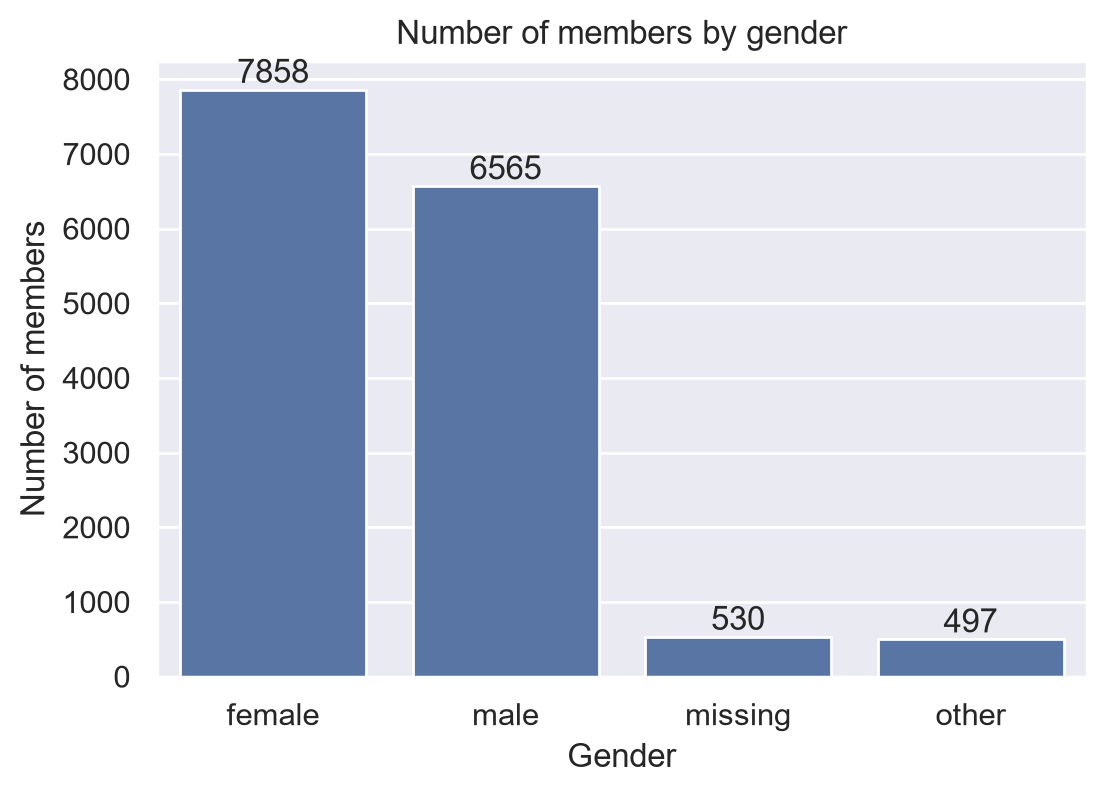

In [28]:
# Count the members of each gender (missing values are labelled "missing" for the plot only)
gender_counts = df["gender"].fillna("missing").value_counts()

# Bar chart
plt.figure(figsize=(6, 4))
ax = sns.barplot(x=gender_counts.index, y=gender_counts.values)
ax.bar_label(ax.containers[0])   # show the number on top of each bar
plt.title("Number of members by gender")
plt.xlabel("Gender")
plt.ylabel("Number of members")
plt.show()

### Gender

`gender` had several spellings of the same category (upper/lower case, extra spaces, abbreviations such as "F" and "M"). 
These were harmonised into three categories: female, male and other. Missing values were kept as NaN.

### Gender distribution

The members are mostly female and male, with similar sizes (roughly half female and 40-45% male). 
"other" and missing values are small groups (about 3% each). 
Because the groups "other" and missing are small, `gender` is unlikely to be a strong variable for the clustering on its own.

Country

In [29]:
df["country"] = df["country"].str.strip().str.lower()

df["country"] = df["country"].replace({
    "portucal": "portugal",
    "pt": "portugal",
    "de": "germany",
    "deutschland": "germany",
    "uk": "united kingdom",
    "gb": "united kingdom",
    "u.k.": "united kingdom",
    "nl": "netherlands",
    "the netherlands": "netherlands",
    "holland": "netherlands",
    "fr": "france",
    "es": "spain",
    "espana": "spain",
    "españa": "spain",
    "ie": "ireland",
})

# Check the result
df["country"].value_counts(dropna=False)

country
portugal          10499
united kingdom     1165
germany             901
spain               741
france              533
netherlands         487
other (europe)      451
NaN                 429
ireland             244
Name: count, dtype: int64

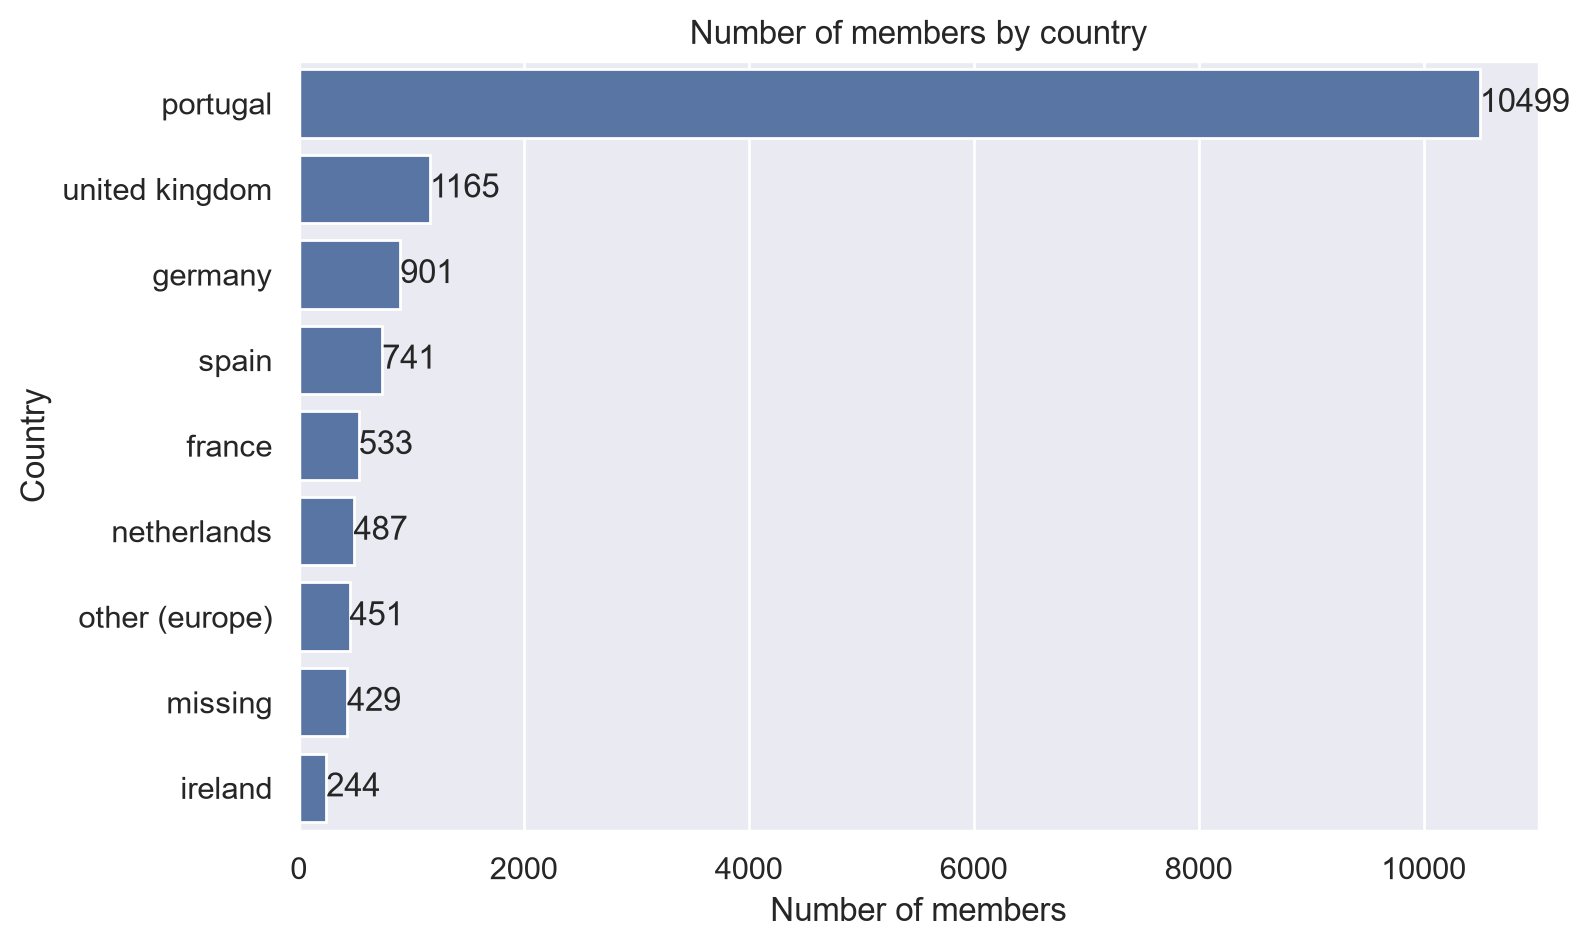

In [30]:
# Count the members of each country (missing values are labelled "missing" for the plot only)
country_counts = df["country"].fillna("missing").value_counts()

# Horizontal bar chart (sorted from the largest to the smallest)
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=country_counts.values, y=country_counts.index)
ax.bar_label(ax.containers[0])   # show the number at the end of each bar
plt.title("Number of members by country")
plt.xlabel("Number of members")
plt.ylabel("Country")
plt.show()

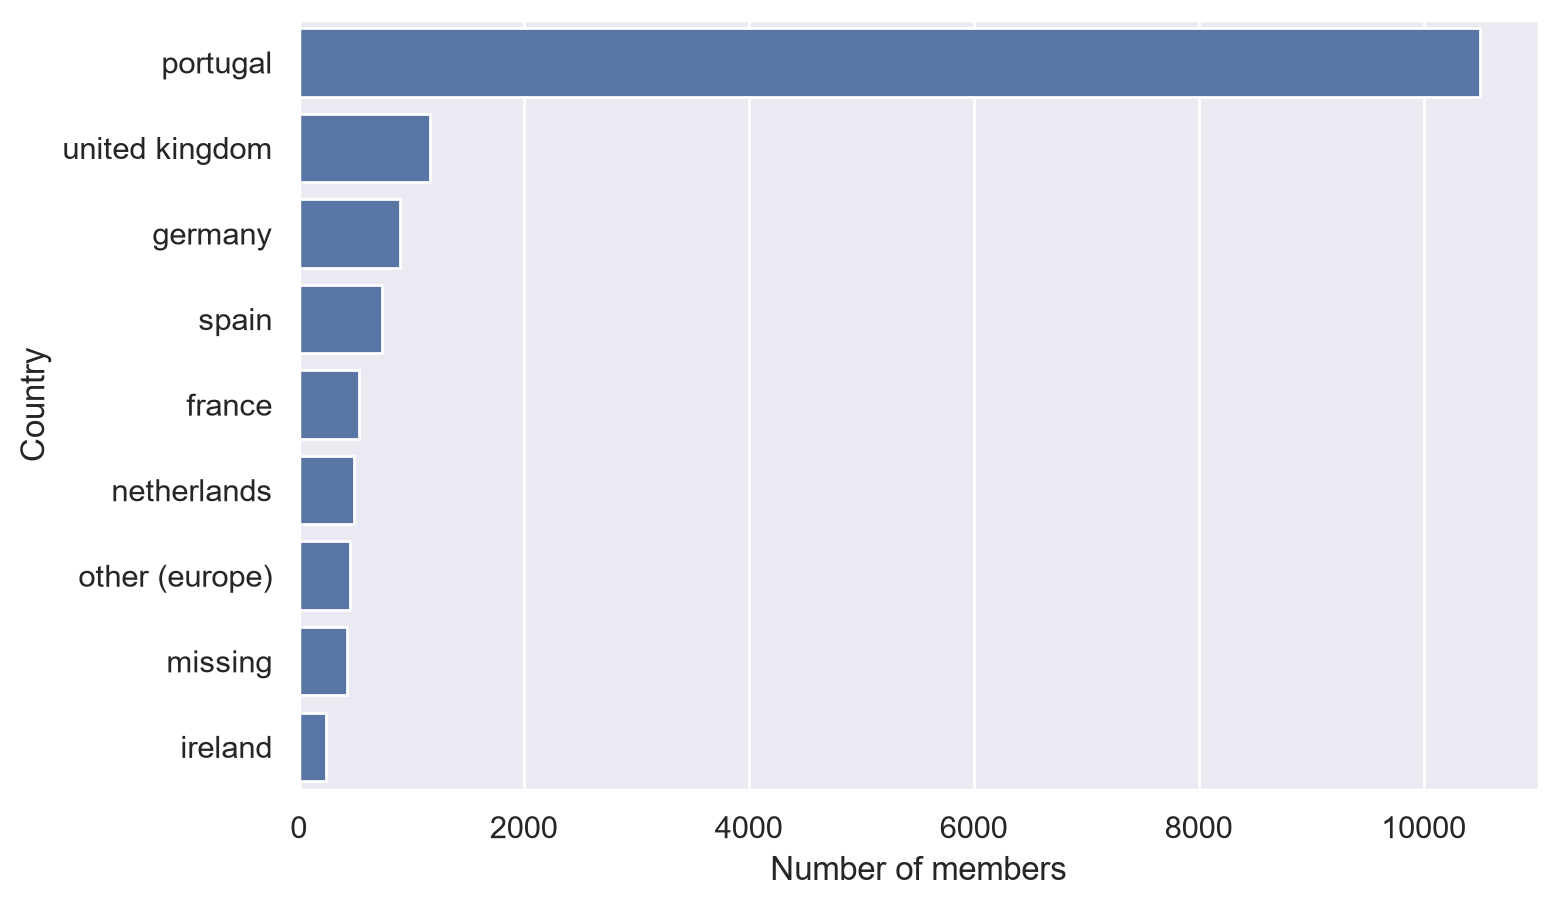

In [31]:
# Count the members of each country 
country_counts = df["country"].fillna("missing").value_counts()

# Calculate percentages
country_percent = country_counts / country_counts.sum() * 100

# Horizontal bar chart (sorted from the largest to the smallest)
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=country_counts.values, y=country_counts.index)

# Show the percentage at the end of each bar
#labels = [f"{p:.1f}%" for p in country_percent.values]
#ax.bar_label(ax.containers[0], labels=labels)

#plt.title("Number of members by country")
plt.xlabel("Number of members")
plt.ylabel("Country")
plt.show()

### Country

`country` had many spellings of the same country (abbreviations such as "pt" or "uk", other languages such as "deutschland" or "espana", 
and a spelling mistake "portucal"). They were harmonised into 8 categories: portugal, united kingdom, germany, spain, france, 
netherlands, ireland and other (europe). Missing values were kept as NaN.


### Country distribution

Portugal represents the large majority of the members, while the other countries are small groups. 
"other (europe)" is a catch-all category and "missing" corresponds to unknown countries. 
This strong imbalance means that `country` may add little information to the clustering unless the small countries are grouped together.

In [32]:
# Clean and standardize plan_tier values
df["plan_tier"] = df["plan_tier"].str.strip().str.lower()

df["plan_tier"] = df["plan_tier"].replace({
    "flex": "flex",
    
    "hot_desk": "hot_desk",
    "hot desk": "hot_desk",
    "hotdesk": "hot_desk",
    
    "full_time": "full_time",
    "full time": "full_time",
    "fulltime": "full_time",
    
    "dedicated_desk": "dedicated_desk",
    "dedicated desk": "dedicated_desk",
    "dedicateddesk": "dedicated_desk",
    
    "private_office": "private_office",
    "private office": "private_office",
    "privateoffice": "private_office",
})

df["plan_tier"].value_counts(dropna=False)

plan_tier
flex              5449
hot_desk          5212
full_time         2471
dedicated_desk    1549
private_office     664
NaN                105
Name: count, dtype: int64

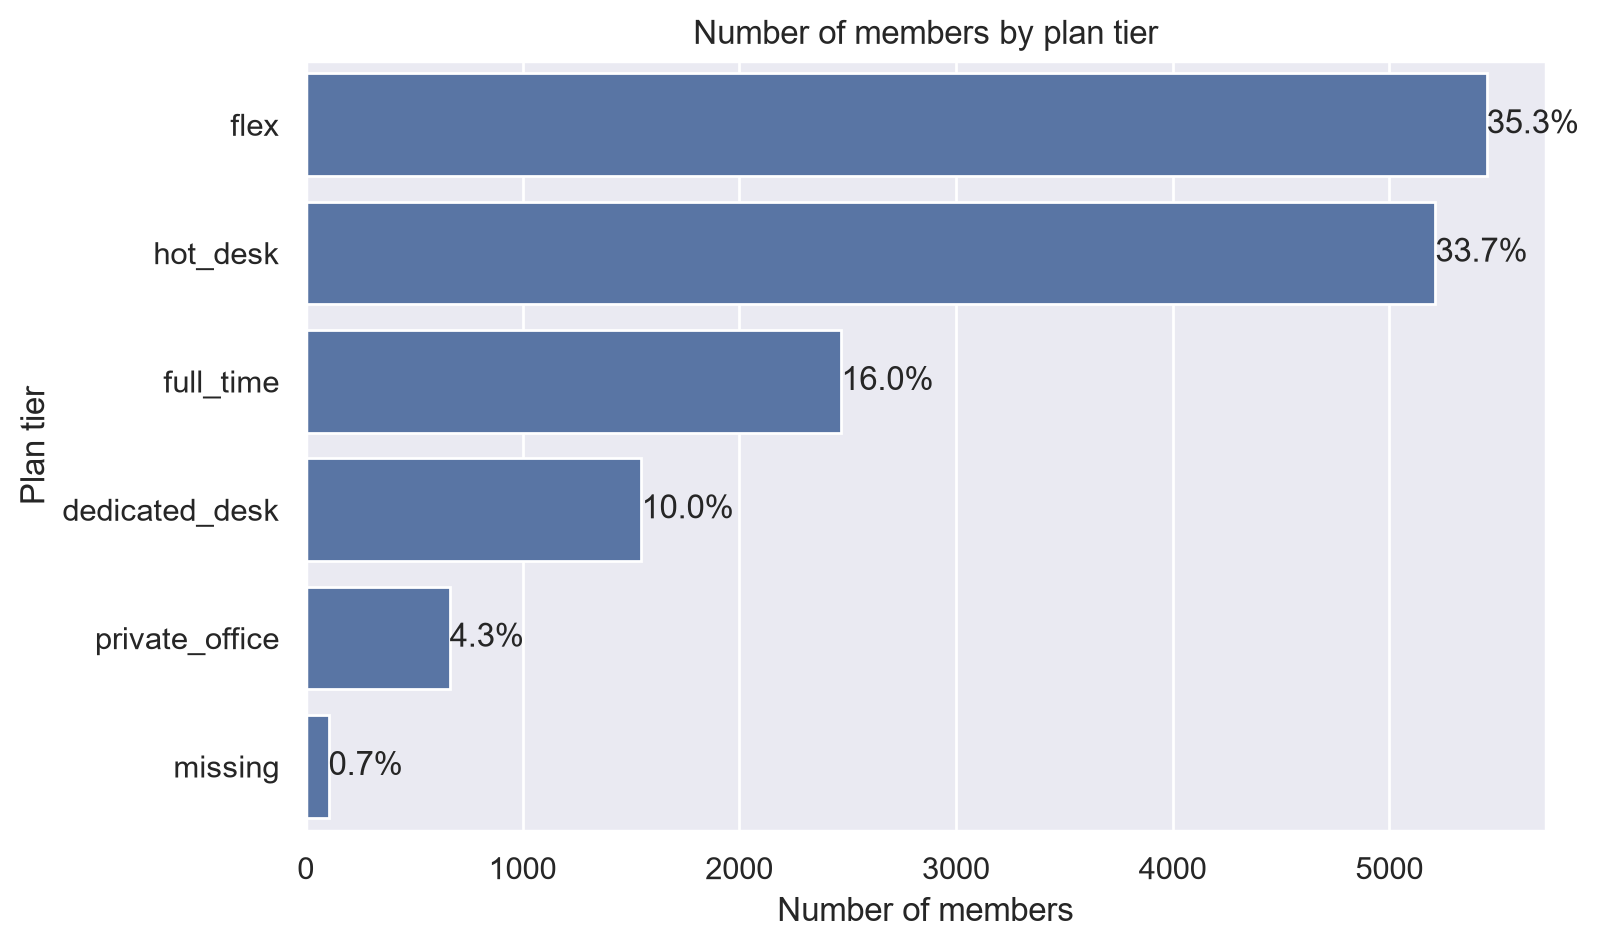

In [33]:
# Count the members of each plan tier
plan_counts = df["plan_tier"].fillna("missing").value_counts()

# Calculate percentages
plan_percent = plan_counts / plan_counts.sum() * 100

# Horizontal bar chart 
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=plan_counts.values, y=plan_counts.index)

# Show the percentage at the end of each bar
labels = [f"{p:.1f}%" for p in plan_percent.values]
ax.bar_label(ax.containers[0], labels=labels)

# White background and no grid
#ax.set_facecolor("white")
#plt.gcf().set_facecolor("white")
#ax.grid(False)

plt.title("Number of members by plan tier")
plt.xlabel("Number of members")
plt.ylabel("Plan tier")
plt.show()

add text explanation 


### Industry

In [34]:
# Clean and standardize industry values
df["industry"] = df["industry"].str.strip().str.lower()

df["industry"] = df["industry"].replace({
    "information technology": "information technology",
    "it": "information technology",
    "tech": "information technology",

    "consulting": "consulting",

    "marketing & pr": "marketing & pr",
    "marketing/pr": "marketing & pr",
    "marketing and pr": "marketing & pr",

    "design & creative": "design & creative",
    "design/creative": "design & creative",
    "design and creative": "design & creative",

    "finance": "finance",

    "other": "other",

    "legal": "legal",

    "education": "education",

    "unknown": "unknown",

    "health": "health",

    "real estate": "real estate",
    "realestate": "real estate",
    "real-estate": "real estate",
})

# Check the result
df["industry"].value_counts(dropna=False)

industry
information technology    3557
consulting                2055
design & creative         1974
marketing & pr            1962
finance                   1219
other                     1175
legal                      878
education                  775
unknown                    693
health                     601
real estate                561
Name: count, dtype: int64

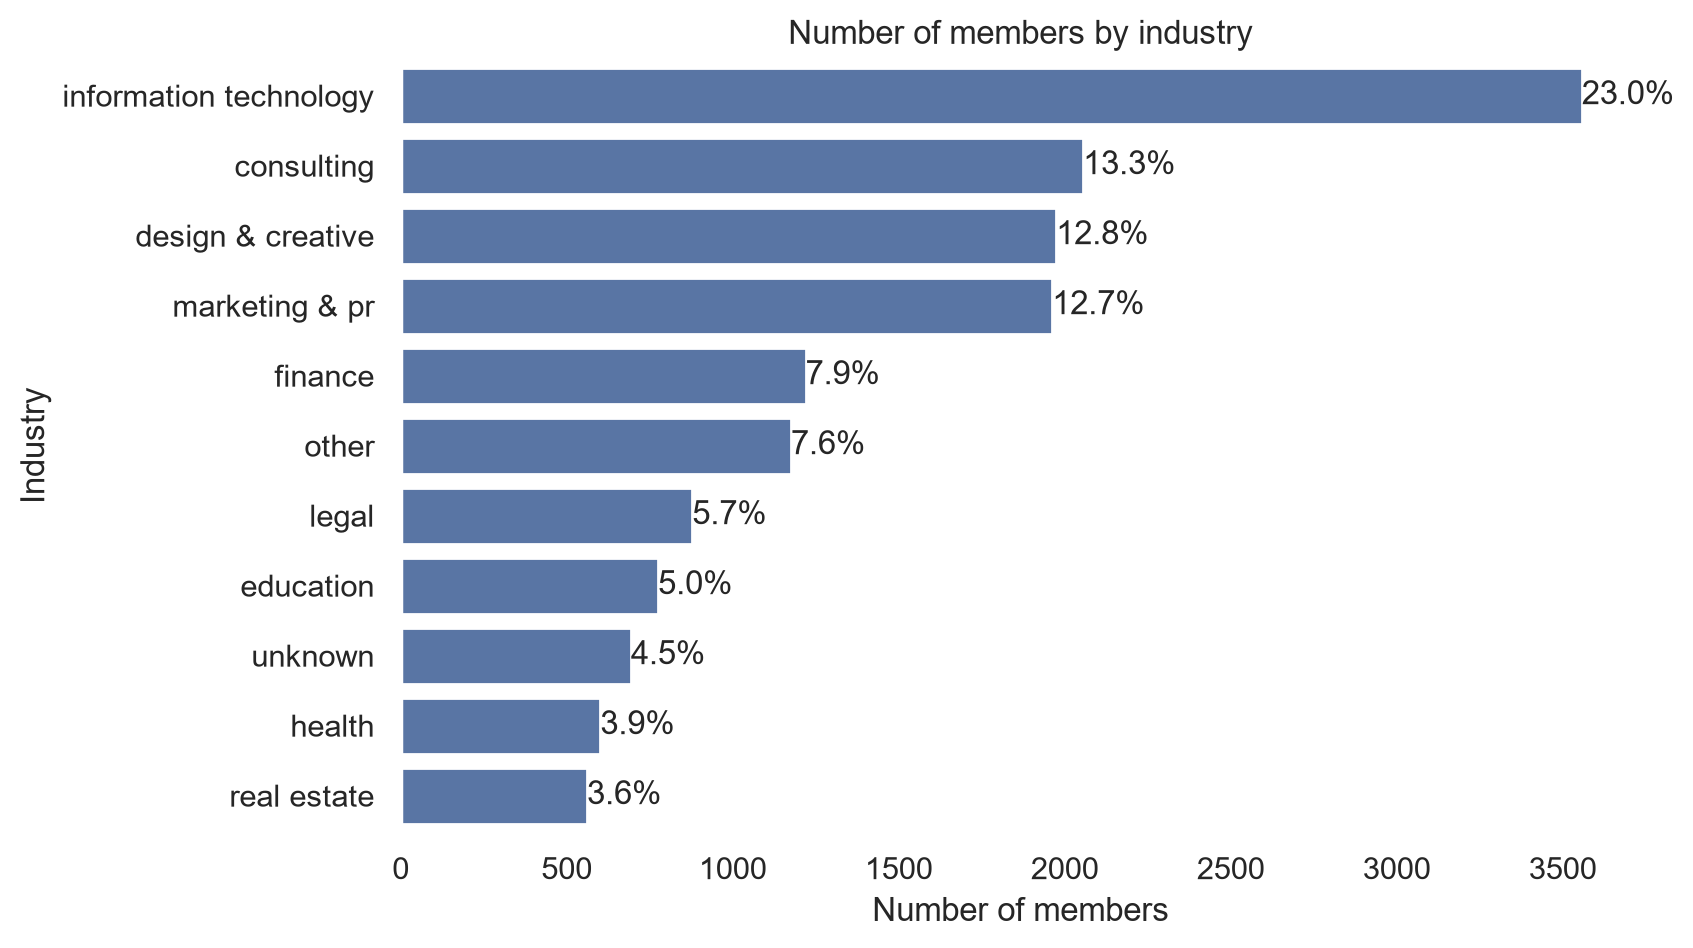

In [35]:
# Count the members of each industry
industry_counts = df["industry"].fillna("missing").value_counts()

# Calculate percentages
industry_percent = industry_counts / industry_counts.sum() * 100

# Horizontal bar chart (sorted from the largest to the smallest)
plt.figure(figsize=(8, 5))
ax = sns.barplot(x=industry_counts.values, y=industry_counts.index)

# Show the percentage at the end of each bar
labels = [f"{p:.1f}%" for p in industry_percent.values]
ax.bar_label(ax.containers[0], labels=labels)

# White background and no grid
ax.set_facecolor("white")
plt.gcf().set_facecolor("white")
ax.grid(False)

plt.title("Number of members by industry")
plt.xlabel("Number of members")
plt.ylabel("Industry")
plt.show()

In [36]:
#add comments !!!!


## Impossible values

We check for values that cannot be true (for example negative counts or ages that are not realistic). 
These are data errors, different from outliers (extreme but possible values).

In [37]:
# Numeric columns that can never be negative (counts, hours, days)
count_cols = ["n_colleagues_on_account", "days_since_last_visit", "total_visits",
              "avg_weekly_visits", "entitled_visits_last_period", "actual_visits_last_period",
              "meeting_room_hours", "event_space_hours", "guest_passes_issued", "n_renewals"]

# Number of negative values in each column
(df[count_cols] < 0).sum()

n_colleagues_on_account        565
days_since_last_visit           56
total_visits                    42
avg_weekly_visits                0
entitled_visits_last_period      0
actual_visits_last_period        0
meeting_room_hours              16
event_space_hours                8
guest_passes_issued              7
n_renewals                      66
dtype: int64

In [38]:
# Range of the age
print(df["age"].min(), df["age"].max())

# Number of members younger than 16 and older than 90
print((df["age"] < 16).sum())
print((df["age"] > 90).sum())

1.0 149.0
98
49


In [39]:
# A week has 7 days: count the values above 7 and equal to 0
print((df["plan_days_per_week"] > 7).sum())
print((df["plan_days_per_week"] == 0).sum())

54
43


In [40]:
# Number of members per year for each date column
for col in ["membership_start", "membership_end", "last_badge_swipe"]:
    print(col)
    print(df[col].dt.year.value_counts().sort_index())
    print()

membership_start
membership_start
2021    7626
2022    4449
2023    3375
Name: count, dtype: int64

membership_end
membership_end
1970    3954
2020      15
2021    1677
2022    3658
2023    6071
2024      75
Name: count, dtype: int64

last_badge_swipe
last_badge_swipe
2020      14
2021    1865
2022    3705
2023    9821
2024      45
Name: count, dtype: int64



In [41]:
# Which exact dates are found in the year 1970?
df.loc[df["membership_end"].dt.year == 1970, "membership_end"].value_counts()

membership_end
1970-01-01    3954
Name: count, dtype: int64

In [42]:
# Placeholder date in membership_end
is_placeholder = df["membership_end"] == "1970-01-01"
print("Members with the placeholder date 1970-01-01:", is_placeholder.sum(),
      f"({is_placeholder.mean() * 100:.1f}%)")

# Among the real end dates (placeholder excluded)
real_end = df[~is_placeholder]
print("End date before start date:", (real_end["membership_end"] < real_end["membership_start"]).sum())
print("Last badge swipe after end date:", (real_end["last_badge_swipe"] > real_end["membership_end"]).sum())

# End dates before the first membership of the company
print("End date before the first membership start:",
      (df["membership_end"] < df["membership_start"].min()).sum())

Members with the placeholder date 1970-01-01: 3954 (25.6%)
End date before start date: 152
Last badge swipe after end date: 213
End date before the first membership start: 3969


### Suspicious year in membership_end

The distribution by year shows that membership_end contains the year 1970 for about 3,950 members (25.6%), 
although all memberships start between 2021 and 2023. 
All these members share one single date (1 January 1970), which suggests a default value used when no end date is recorded.
A possible explanation is that these members are still active, but the data does not confirm it.

## Distributions and outliers

We look at the distribution of each numeric variable to understand its shape and to spot extreme values. 
An outlier is an extreme value that is not necessarily an error: it may be a real, very active or very profitable member.

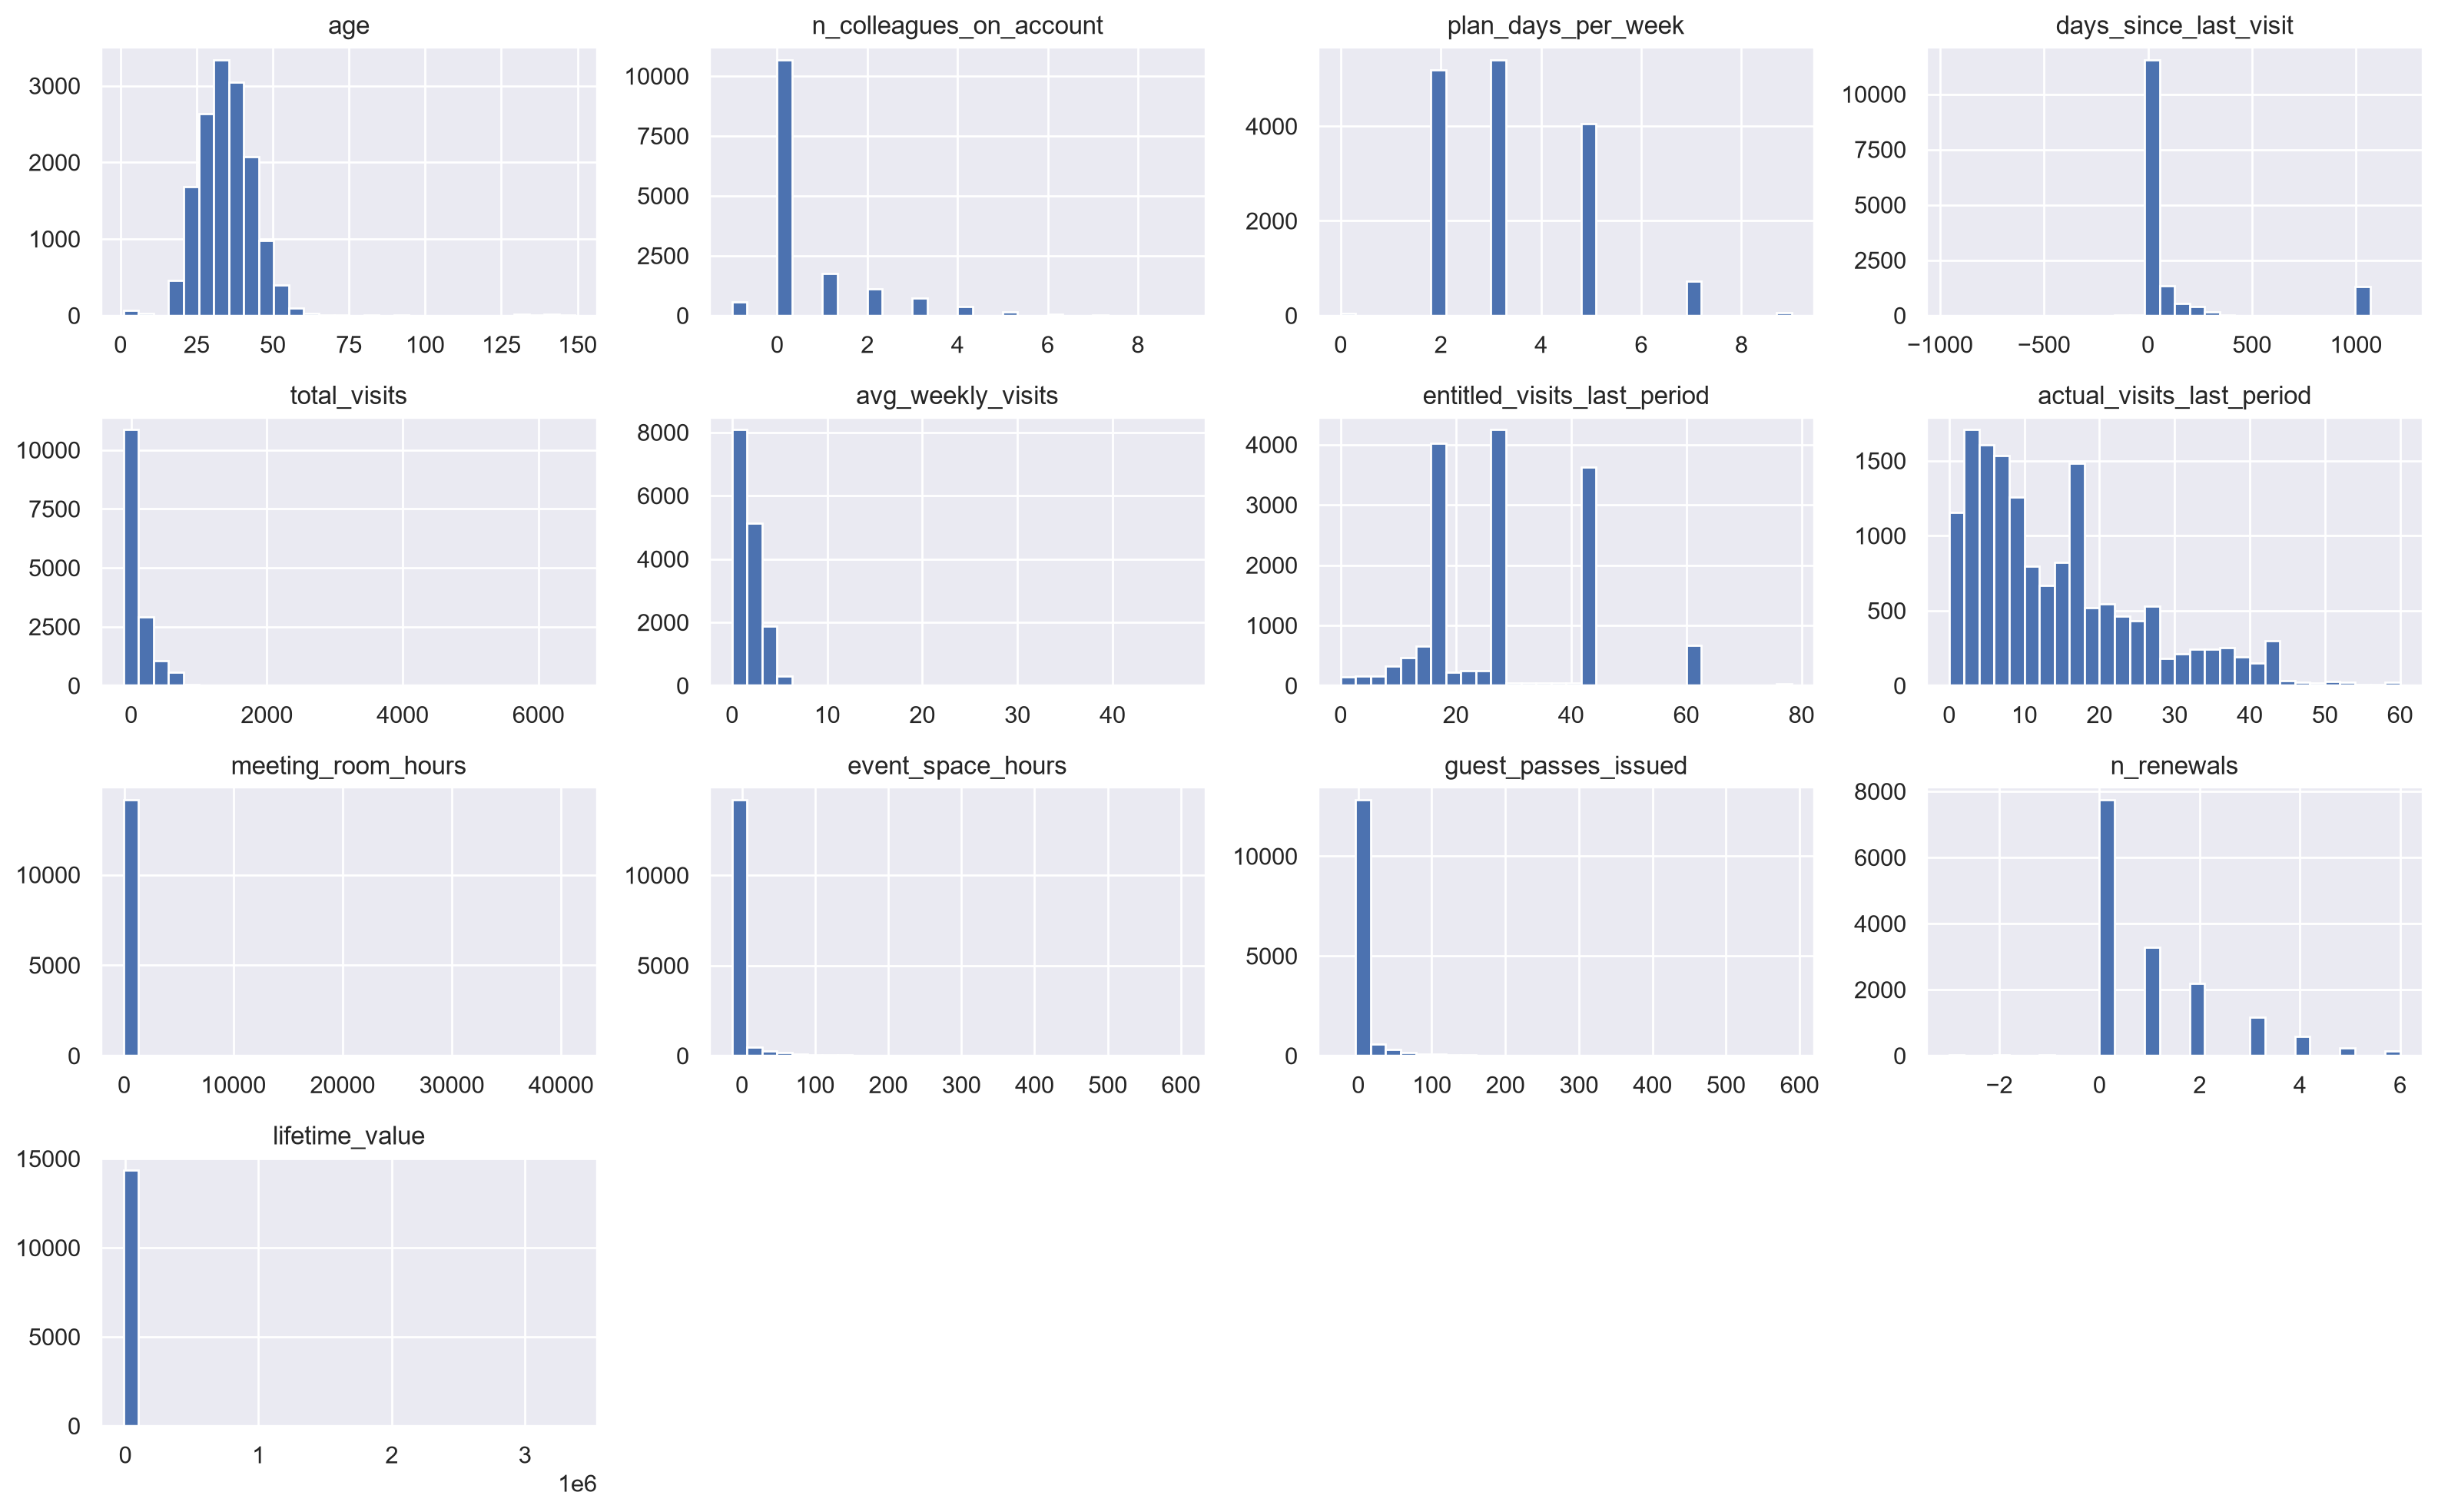

In [43]:
import matplotlib.pyplot as plt

# Numeric variables to analyse (binary variables are excluded)
num_cols = ["age", "n_colleagues_on_account", "plan_days_per_week", "days_since_last_visit",
            "total_visits", "avg_weekly_visits", "entitled_visits_last_period",
            "actual_visits_last_period", "meeting_room_hours", "event_space_hours",
            "guest_passes_issued", "n_renewals", "lifetime_value"]

# One histogram per variable
df[num_cols].hist(bins=30, figsize=(16, 10))
plt.tight_layout()
plt.show()

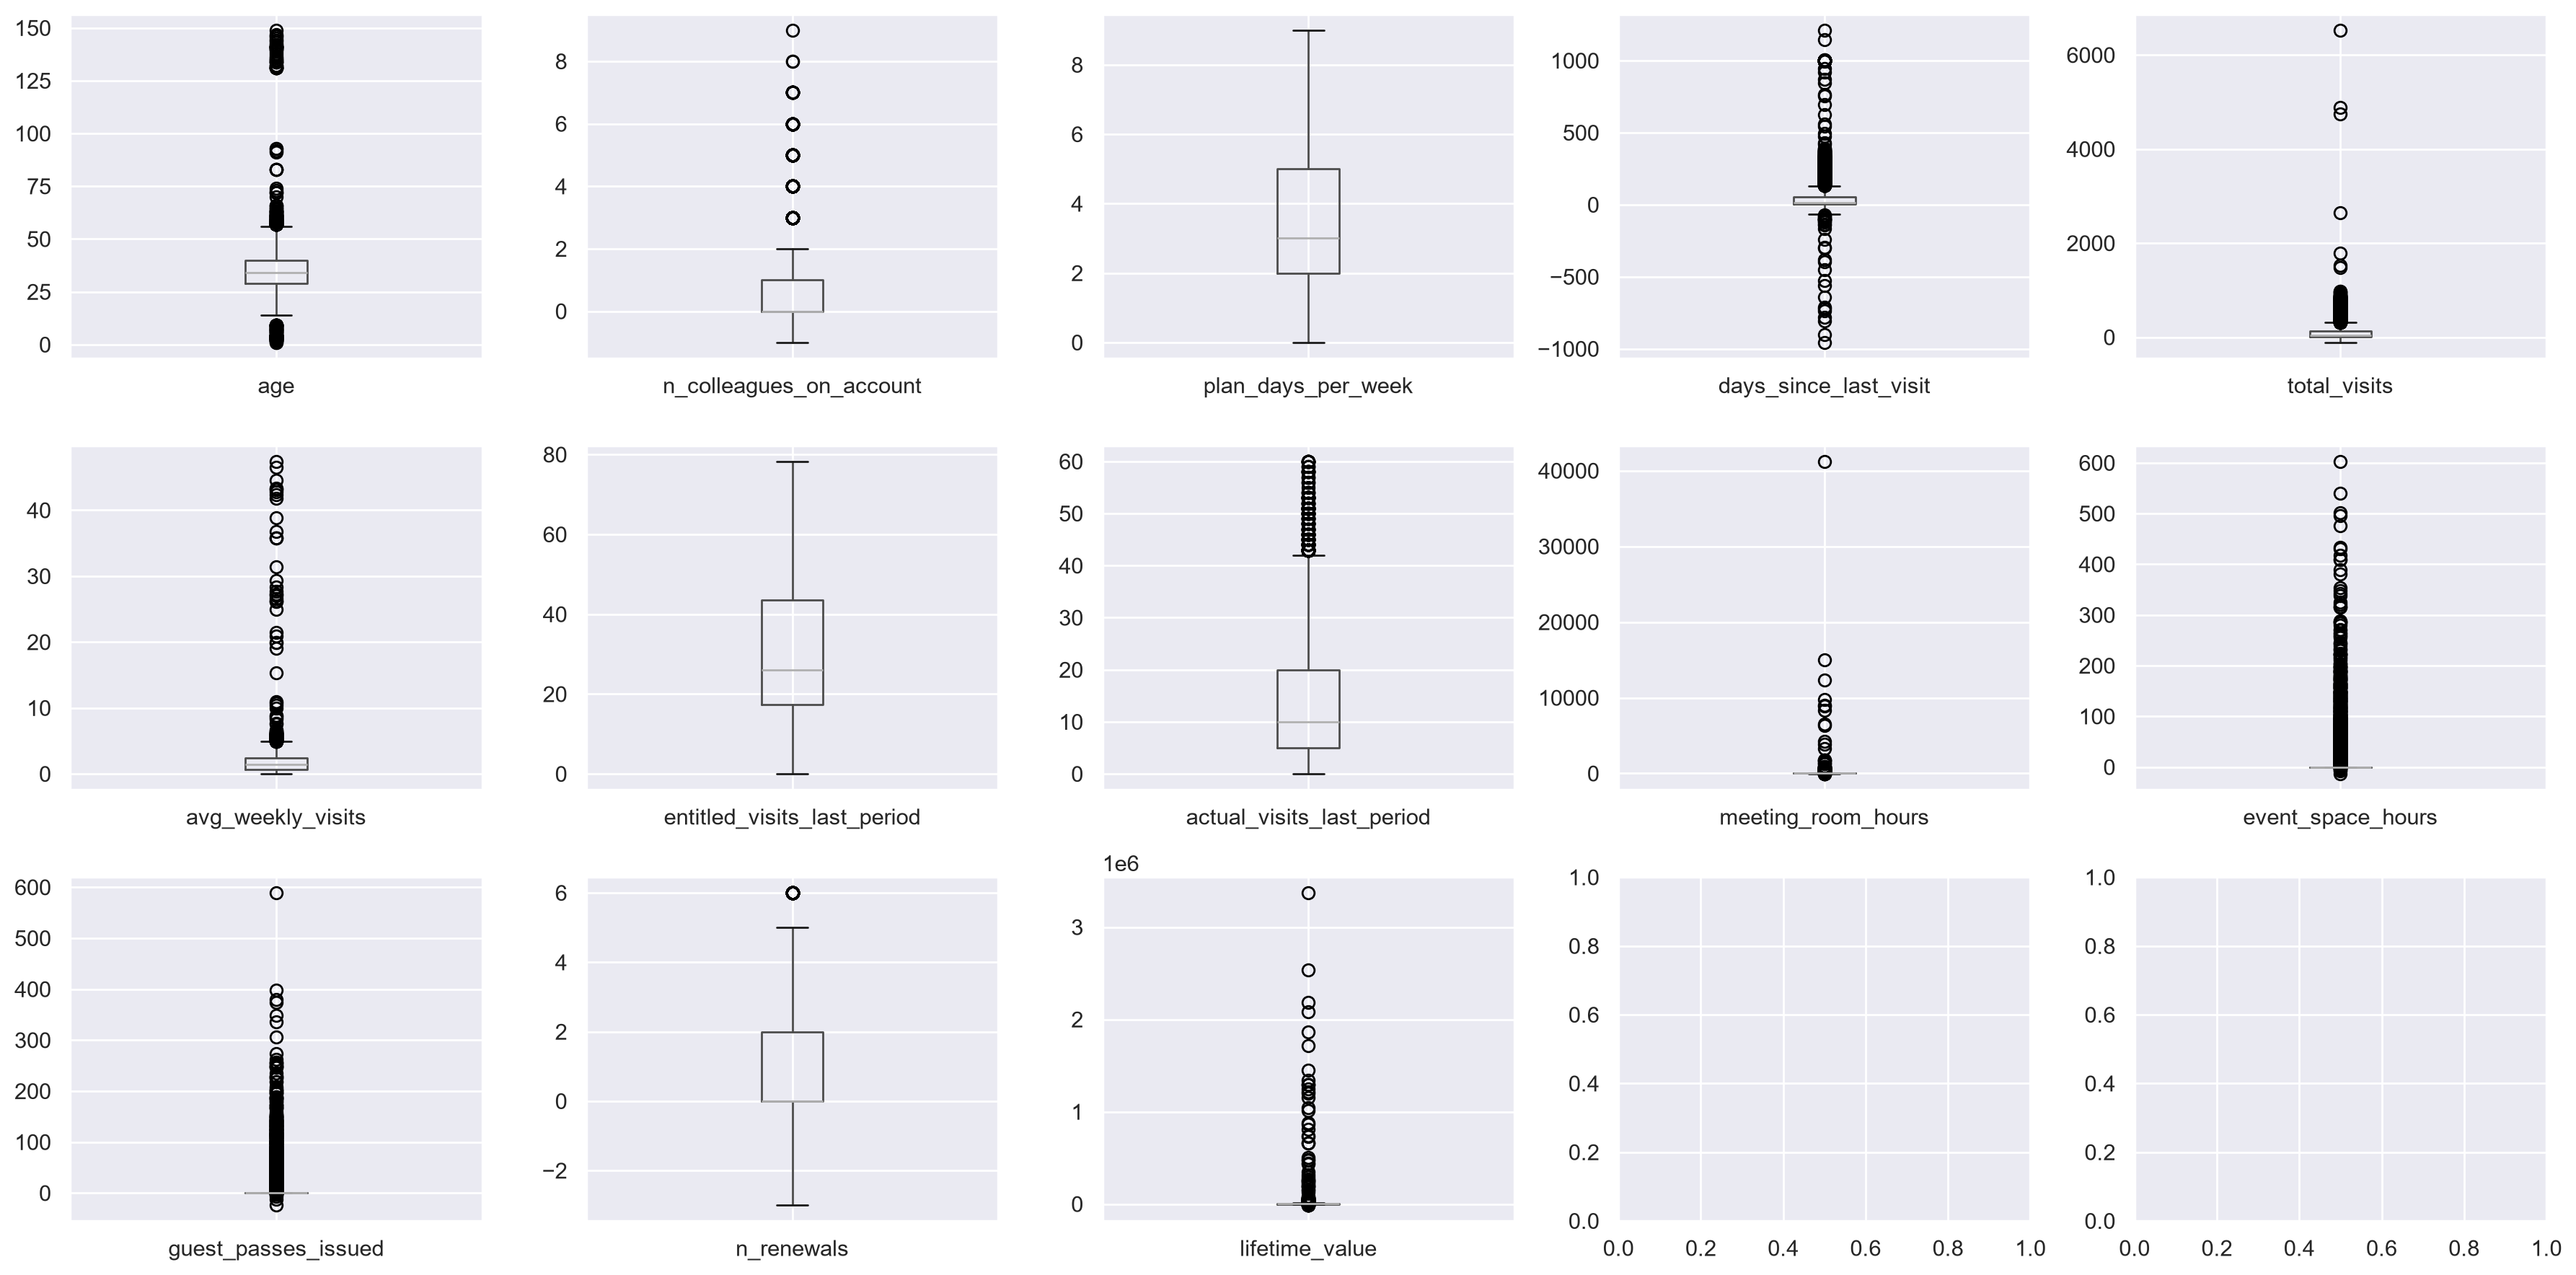

In [44]:
# One boxplot per variable 
fig, axes = plt.subplots(3, 5, figsize=(18, 9))
for ax, col in zip(axes.flat, num_cols):
    df.boxplot(column=col, ax=ax)
plt.tight_layout()
plt.show()

In [45]:
# Goal: for each numeric variable, find the values that are "unusually" small or large
# Rule used (IQR rule): a value is an outlier if it is outside the interval
#   [Q1 - 1.5 * IQR ; Q3 + 1.5 * IQR]
# Q1 = value below which 25% of the members are, Q3 = value below which 75% of the members are
# IQR = Q3 - Q1 (the range of the "middle half" of the members)

results = []

for col in num_cols:
    values = df[col].dropna()          # ignore the missing values

    q1 = values.quantile(0.25)         # 1st quartile
    q3 = values.quantile(0.75)         # 3rd quartile
    iqr = q3 - q1                      # interquartile range

    lower = q1 - 1.5 * iqr             # below this limit = unusually small
    upper = q3 + 1.5 * iqr             # above this limit = unusually large

    n_low = (values < lower).sum()     # number of unusually small values
    n_high = (values > upper).sum()    # number of unusually large values
    pct = round((n_low + n_high) / len(values) * 100, 1)   # percentage of outliers

    results.append([col, q1, q3, lower, upper, values.min(), values.max(), n_low, n_high, pct])

# Put the results in a table
outliers_table = pd.DataFrame(results, columns=["variable", "q1", "q3", "lower_limit", "upper_limit",
                                                "min", "max", "n_below", "n_above", "pct_outliers"])
outliers_table.round(1)

,variable,q1,q3,lower_limit,upper_limit,min,max,n_below,n_above,pct_outliers
0,age,29.0,40.0,12.5,56.5,1.0,149.0,97,160,1.7
1,n_colleagues_on_account,0.0,1.0,-1.5,2.5,-1.0,9.0,0,1323,8.6
2,plan_days_per_week,2.0,5.0,-2.5,9.5,0.0,9.0,0,0,0.0
3,days_since_last_visit,4.0,55.0,-72.5,131.5,-956.0,1212.0,31,2471,16.2
4,total_visits,8.0,132.0,-178.0,318.0,-112.0,6530.0,0,1730,11.2
5,avg_weekly_visits,0.7,2.4,-1.8,5.0,0.0,47.4,0,312,2.0
6,entitled_visits_last_period,17.4,43.5,-21.7,82.6,0.0,78.3,0,0,0.0
7,actual_visits_last_period,5.0,20.0,-17.5,42.5,0.0,60.0,0,380,2.5
8,meeting_room_hours,0.0,7.2,-10.8,18.0,-56.6,41220.0,6,2938,20.8
9,event_space_hours,0.0,0.0,0.0,0.0,-13.5,602.8,8,1759,11.4


In [46]:
pd.set_option('display.float_format', lambda x: '%.2f' % x)
print("Numerical Descriptive Statistics:")
df.describe().T

Numerical Descriptive Statistics:


,count,mean,min,25%,50%,75%,max,std
age,14893.00,34.86,1.00,29.00,34.00,40.00,149.00,10.40
n_colleagues_on_account,15450.00,0.54,-1.00,0.00,0.00,1.00,9.00,1.18
plan_days_per_week,15450.00,3.39,0.00,2.00,3.00,5.00,9.00,1.46
membership_start,15450,2022-03-15 18:14:12.815534,2021-01-01 00:00:00,2021-06-02 00:00:00,2022-01-06 00:00:00,2022-11-03 00:00:00,2023-12-30 00:00:00,NaN
membership_end,15450,2009-05-25 17:09:15.029126,1970-01-01 00:00:00,1970-01-01 00:00:00,2022-08-21 00:00:00,2023-06-09 00:00:00,2024-01-01 00:00:00,NaN
last_badge_swipe,15450,2023-02-13 20:05:41.126213,2020-09-06 00:00:00,2022-08-11 00:00:00,2023-05-06 00:00:00,2023-10-17 00:00:00,2024-04-28 00:00:00,NaN
days_since_last_visit,15450.00,117.19,-956.00,4.00,13.00,55.00,1212.00,275.64
total_visits,15450.00,110.39,-112.00,8.00,34.00,132.00,6530.00,182.94
avg_weekly_visits,15450.00,1.78,0.00,0.71,1.42,2.41,47.40,1.94
entitled_visits_last_period,15450.00,27.51,0.00,17.39,26.09,43.48,78.27,13.48


In [47]:
print("Categorical Descriptive Statistics:")
df.describe(include=['str'])

Categorical Descriptive Statistics:


,member_id,gender,industry,country,plan_tier
count,15450,14920,15450,15021,15345
unique,15450,3,11,8,5
top,CW000001,female,information technology,portugal,flex
freq,1,7858,3557,10499,5449


In [48]:
numerical_columns = df.select_dtypes(include=[np.number]).columns
df_num = df[numerical_columns]
results = pd.DataFrame(index=df_num.columns)

results['Mean'] = df_num.mean()

results['Median'] = df_num.median()

results['Mode'] = df_num.mode().iloc[0]

pd.set_option('display.float_format', lambda x: '%.2f' % x)
pd.set_option('display.max_columns', None)
print("Table:")
print(results)

Table:
                               Mean  Median   Mode
age                           34.86   34.00  34.00
n_colleagues_on_account        0.54    0.00   0.00
plan_days_per_week             3.39    3.00   3.00
days_since_last_visit        117.19   13.00 999.00
total_visits                 110.39   34.00   5.00
avg_weekly_visits              1.78    1.42   2.70
entitled_visits_last_period   27.51   26.09  26.09
actual_visits_last_period     13.80   10.00  17.00
meeting_room_hours            33.09    0.00   0.00
event_space_hours              5.12    0.00   0.00
guest_passes_issued            6.16    0.00   0.00
uses_print                     0.32    0.00   0.00
n_renewals                     1.01    0.00   0.00
lifetime_value              6398.77  825.12   0.00


In [49]:
results1 = pd.DataFrame(index=df_num.columns)
results1['Range (Max-Min)'] = df_num.max() - df_num.min()

results1['Skew'] = df_num.skew()

def classificar_simetria(skew):
    if skew > 1 or skew < -1:
        return "Highly assymetrical"
    elif skew > 0.5 or skew < -0.5:
        return "Moderately assymetrical"
    else:
        return "Approximately symetrical"

results1['Skew type'] = results1['Skew'].apply(classificar_simetria)

pd.set_option('display.float_format', lambda x: '%.2f' % x)
pd.set_option('display.max_columns', None)
print("Table:")
print(results1)

Table:
                             Range (Max-Min)  Skew                Skew type
age                                   148.00  3.03      Highly assymetrical
n_colleagues_on_account                10.00  2.12      Highly assymetrical
plan_days_per_week                      9.00  0.93  Moderately assymetrical
days_since_last_visit                2168.00  2.72      Highly assymetrical
total_visits                         6642.00  6.82      Highly assymetrical
avg_weekly_visits                      47.40 10.27      Highly assymetrical
entitled_visits_last_period            78.27  0.73  Moderately assymetrical
actual_visits_last_period              60.00  1.06      Highly assymetrical
meeting_room_hours                  41276.60 70.80      Highly assymetrical
event_space_hours                     616.30  9.22      Highly assymetrical
guest_passes_issued                   613.00  7.01      Highly assymetrical
uses_print                              1.00  0.76  Moderately assymetrical
n_ren

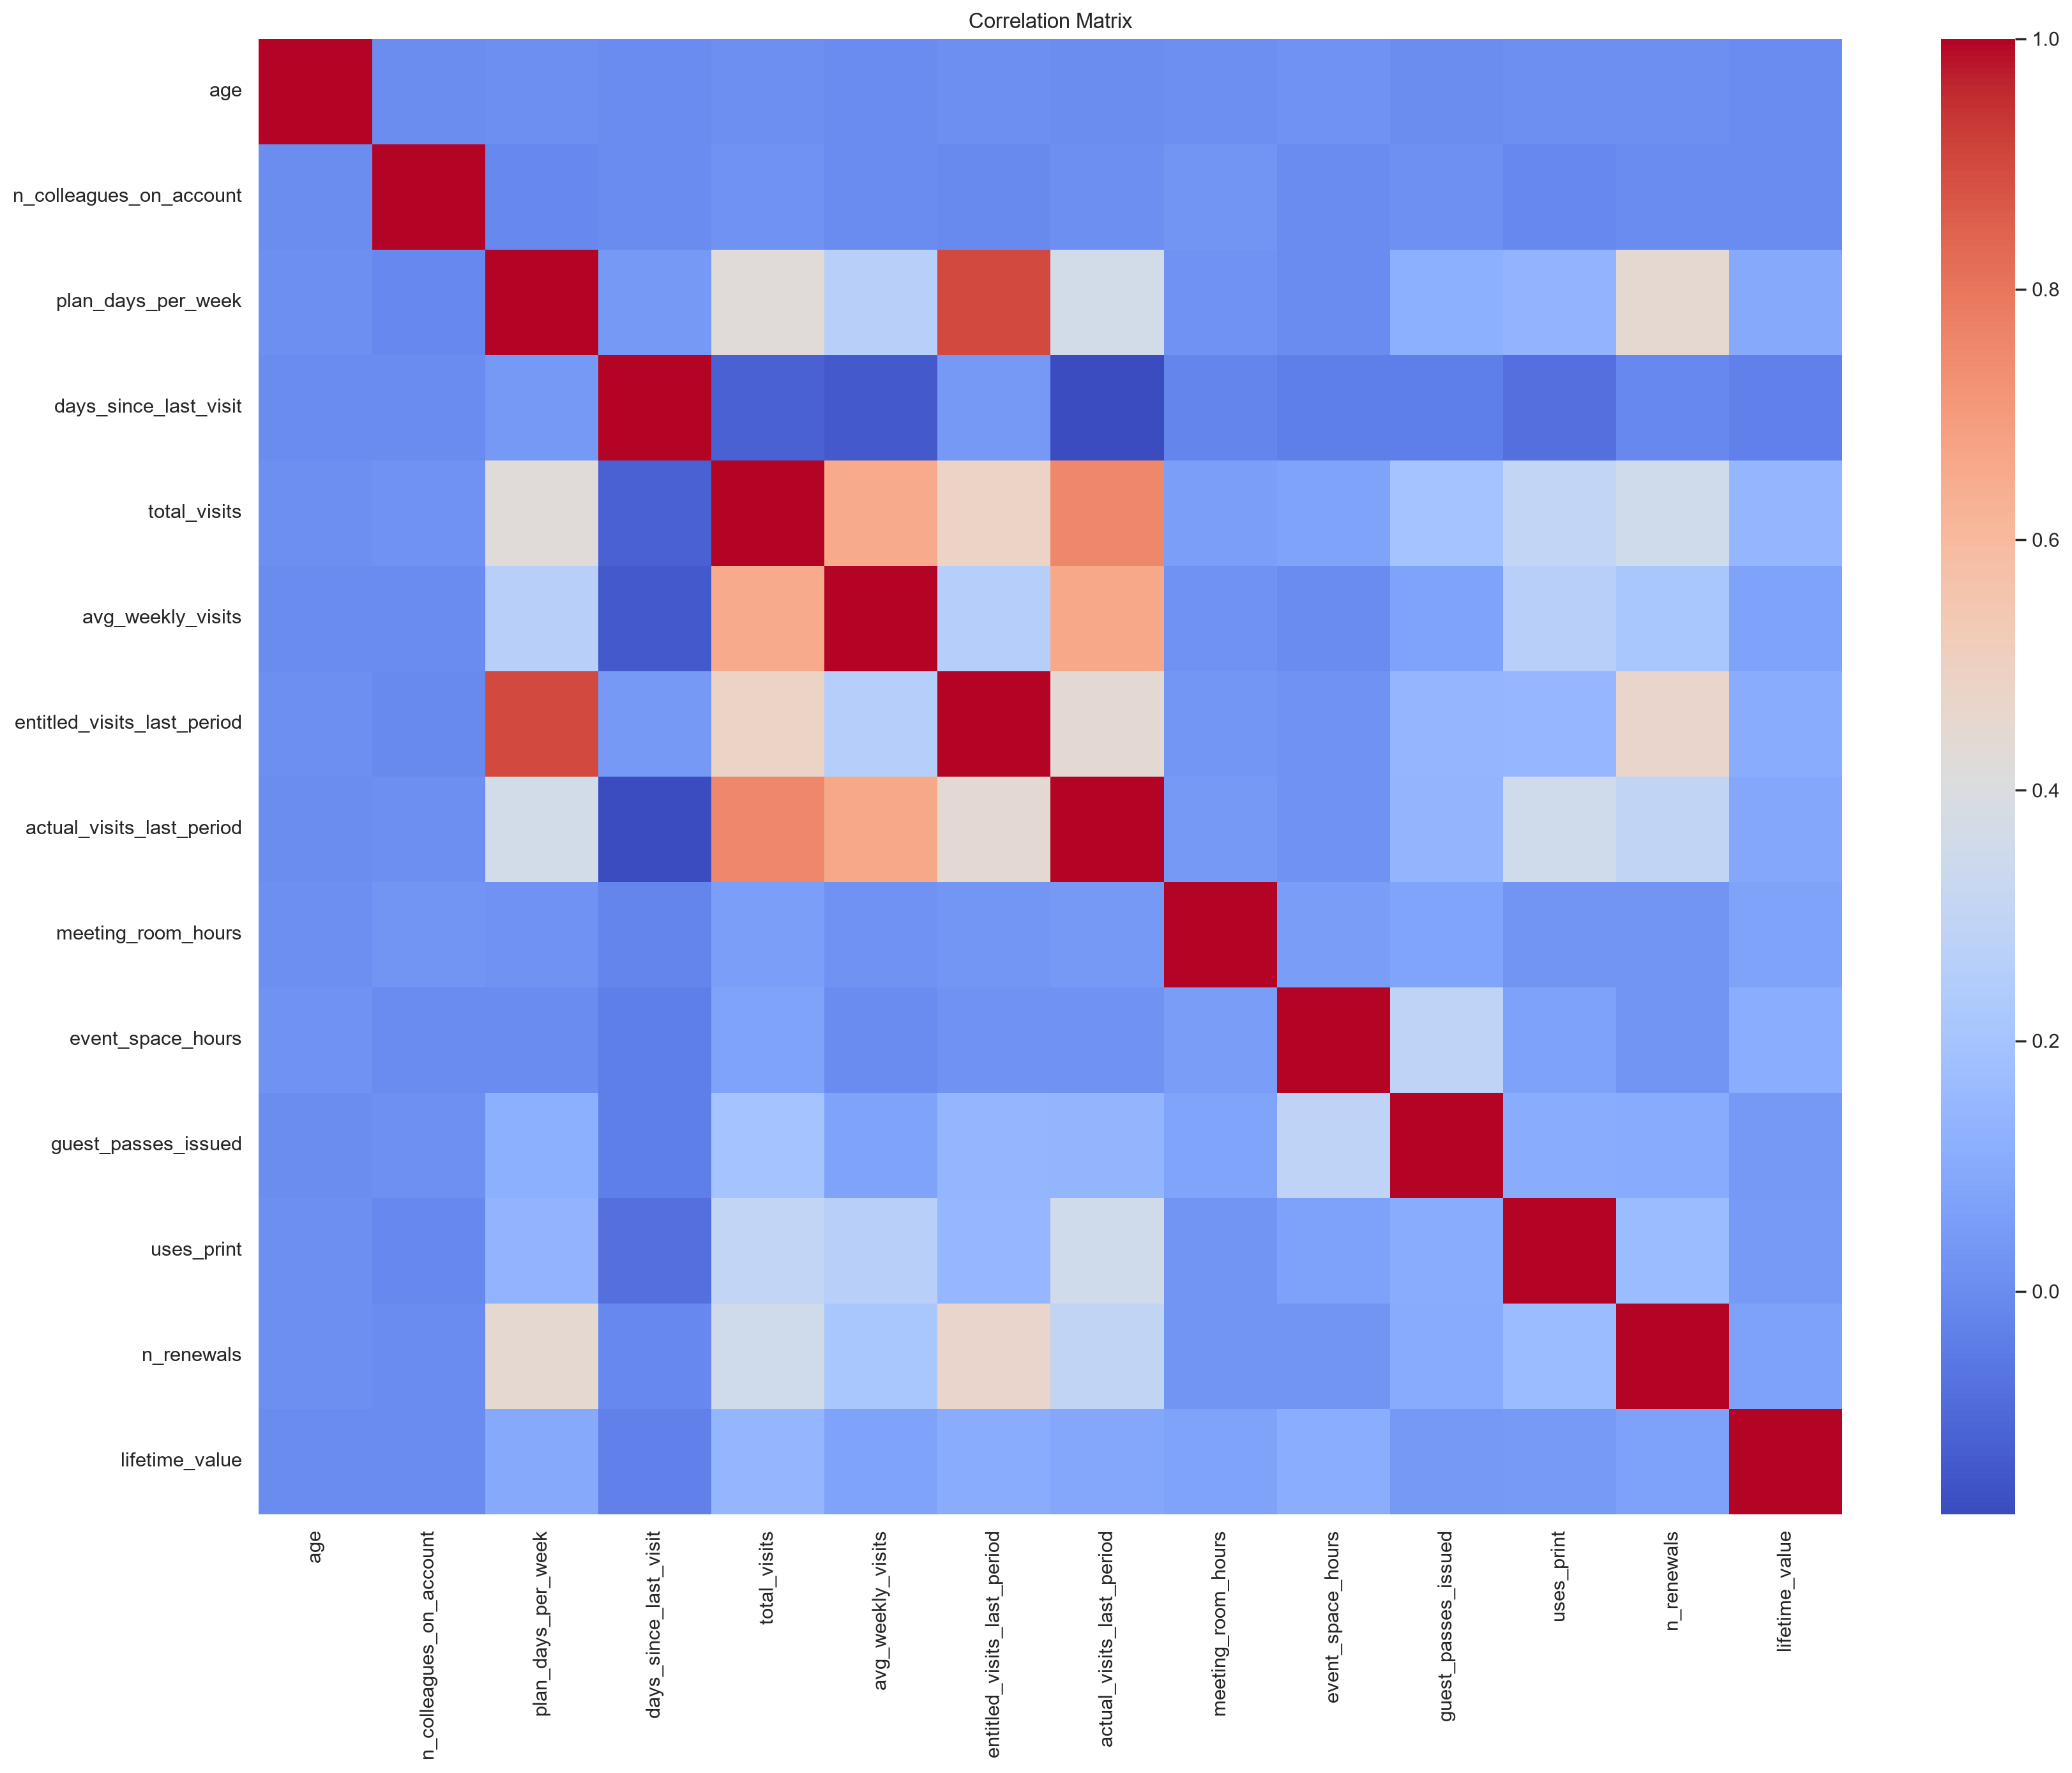

In [50]:
plt.figure(figsize=(20, 15)) 
corr = df.select_dtypes(include=['float64', 'int64']).corr()
sns.heatmap(corr, annot=False, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix')
plt.show()

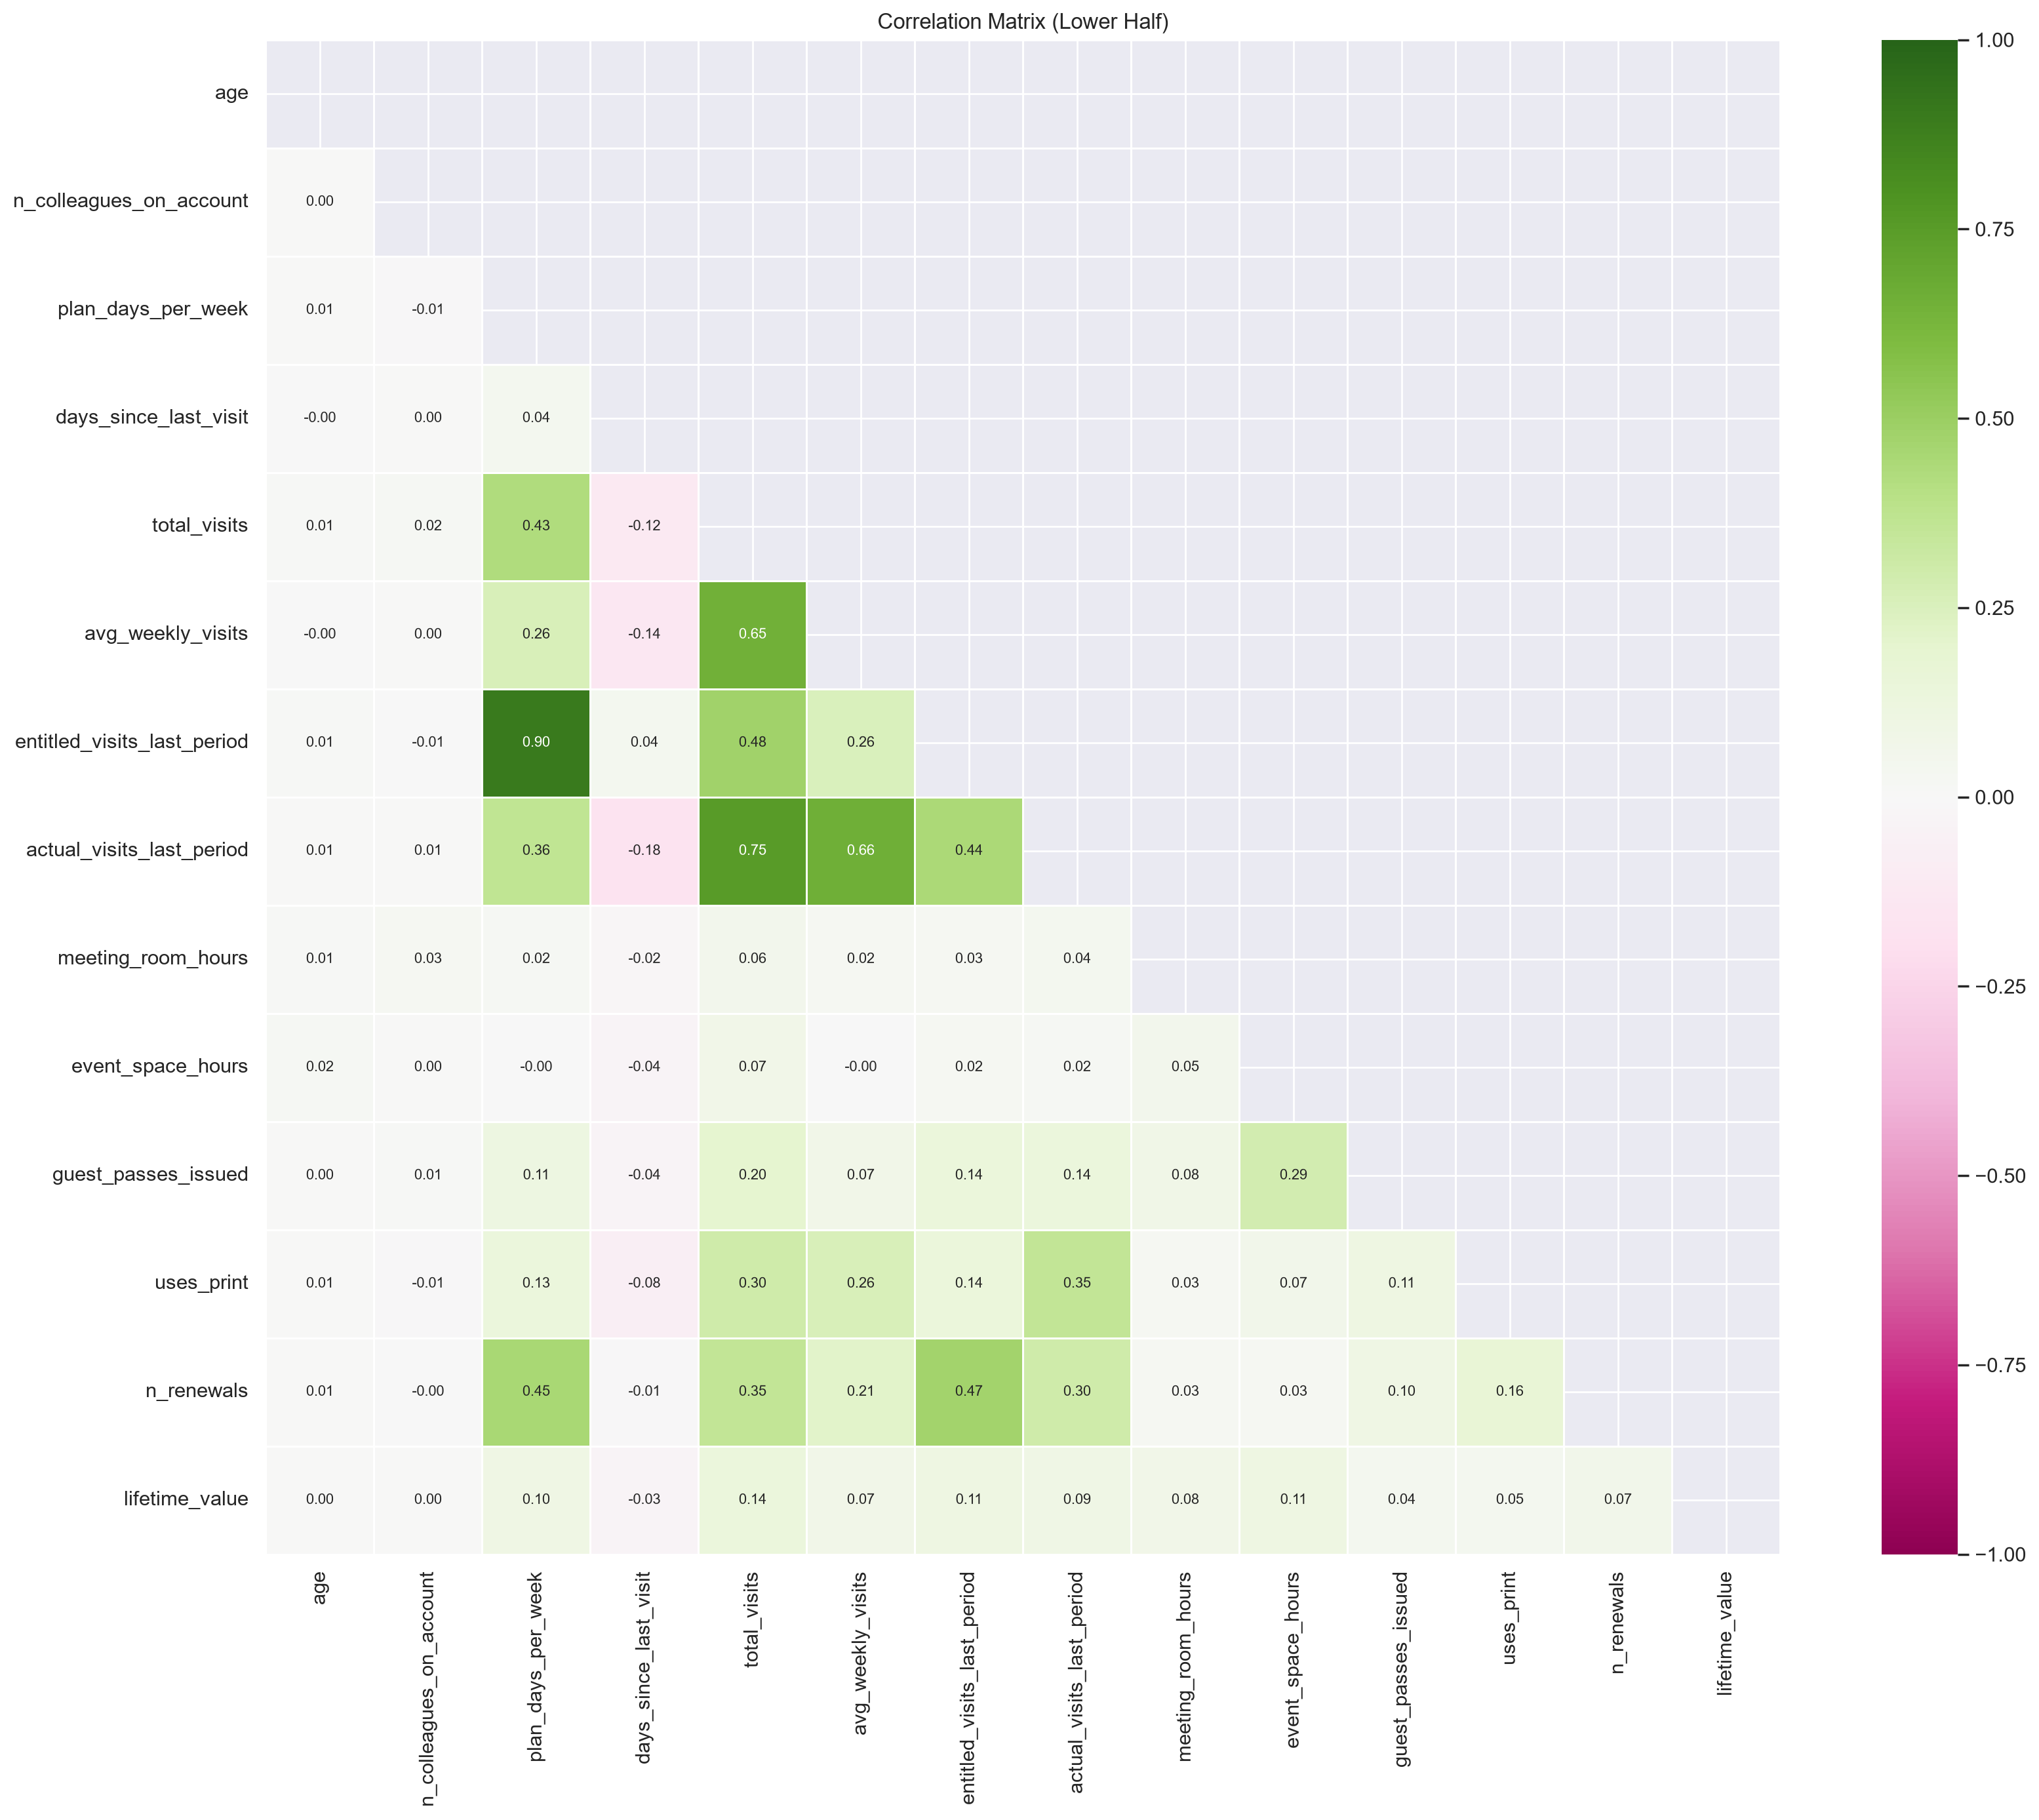

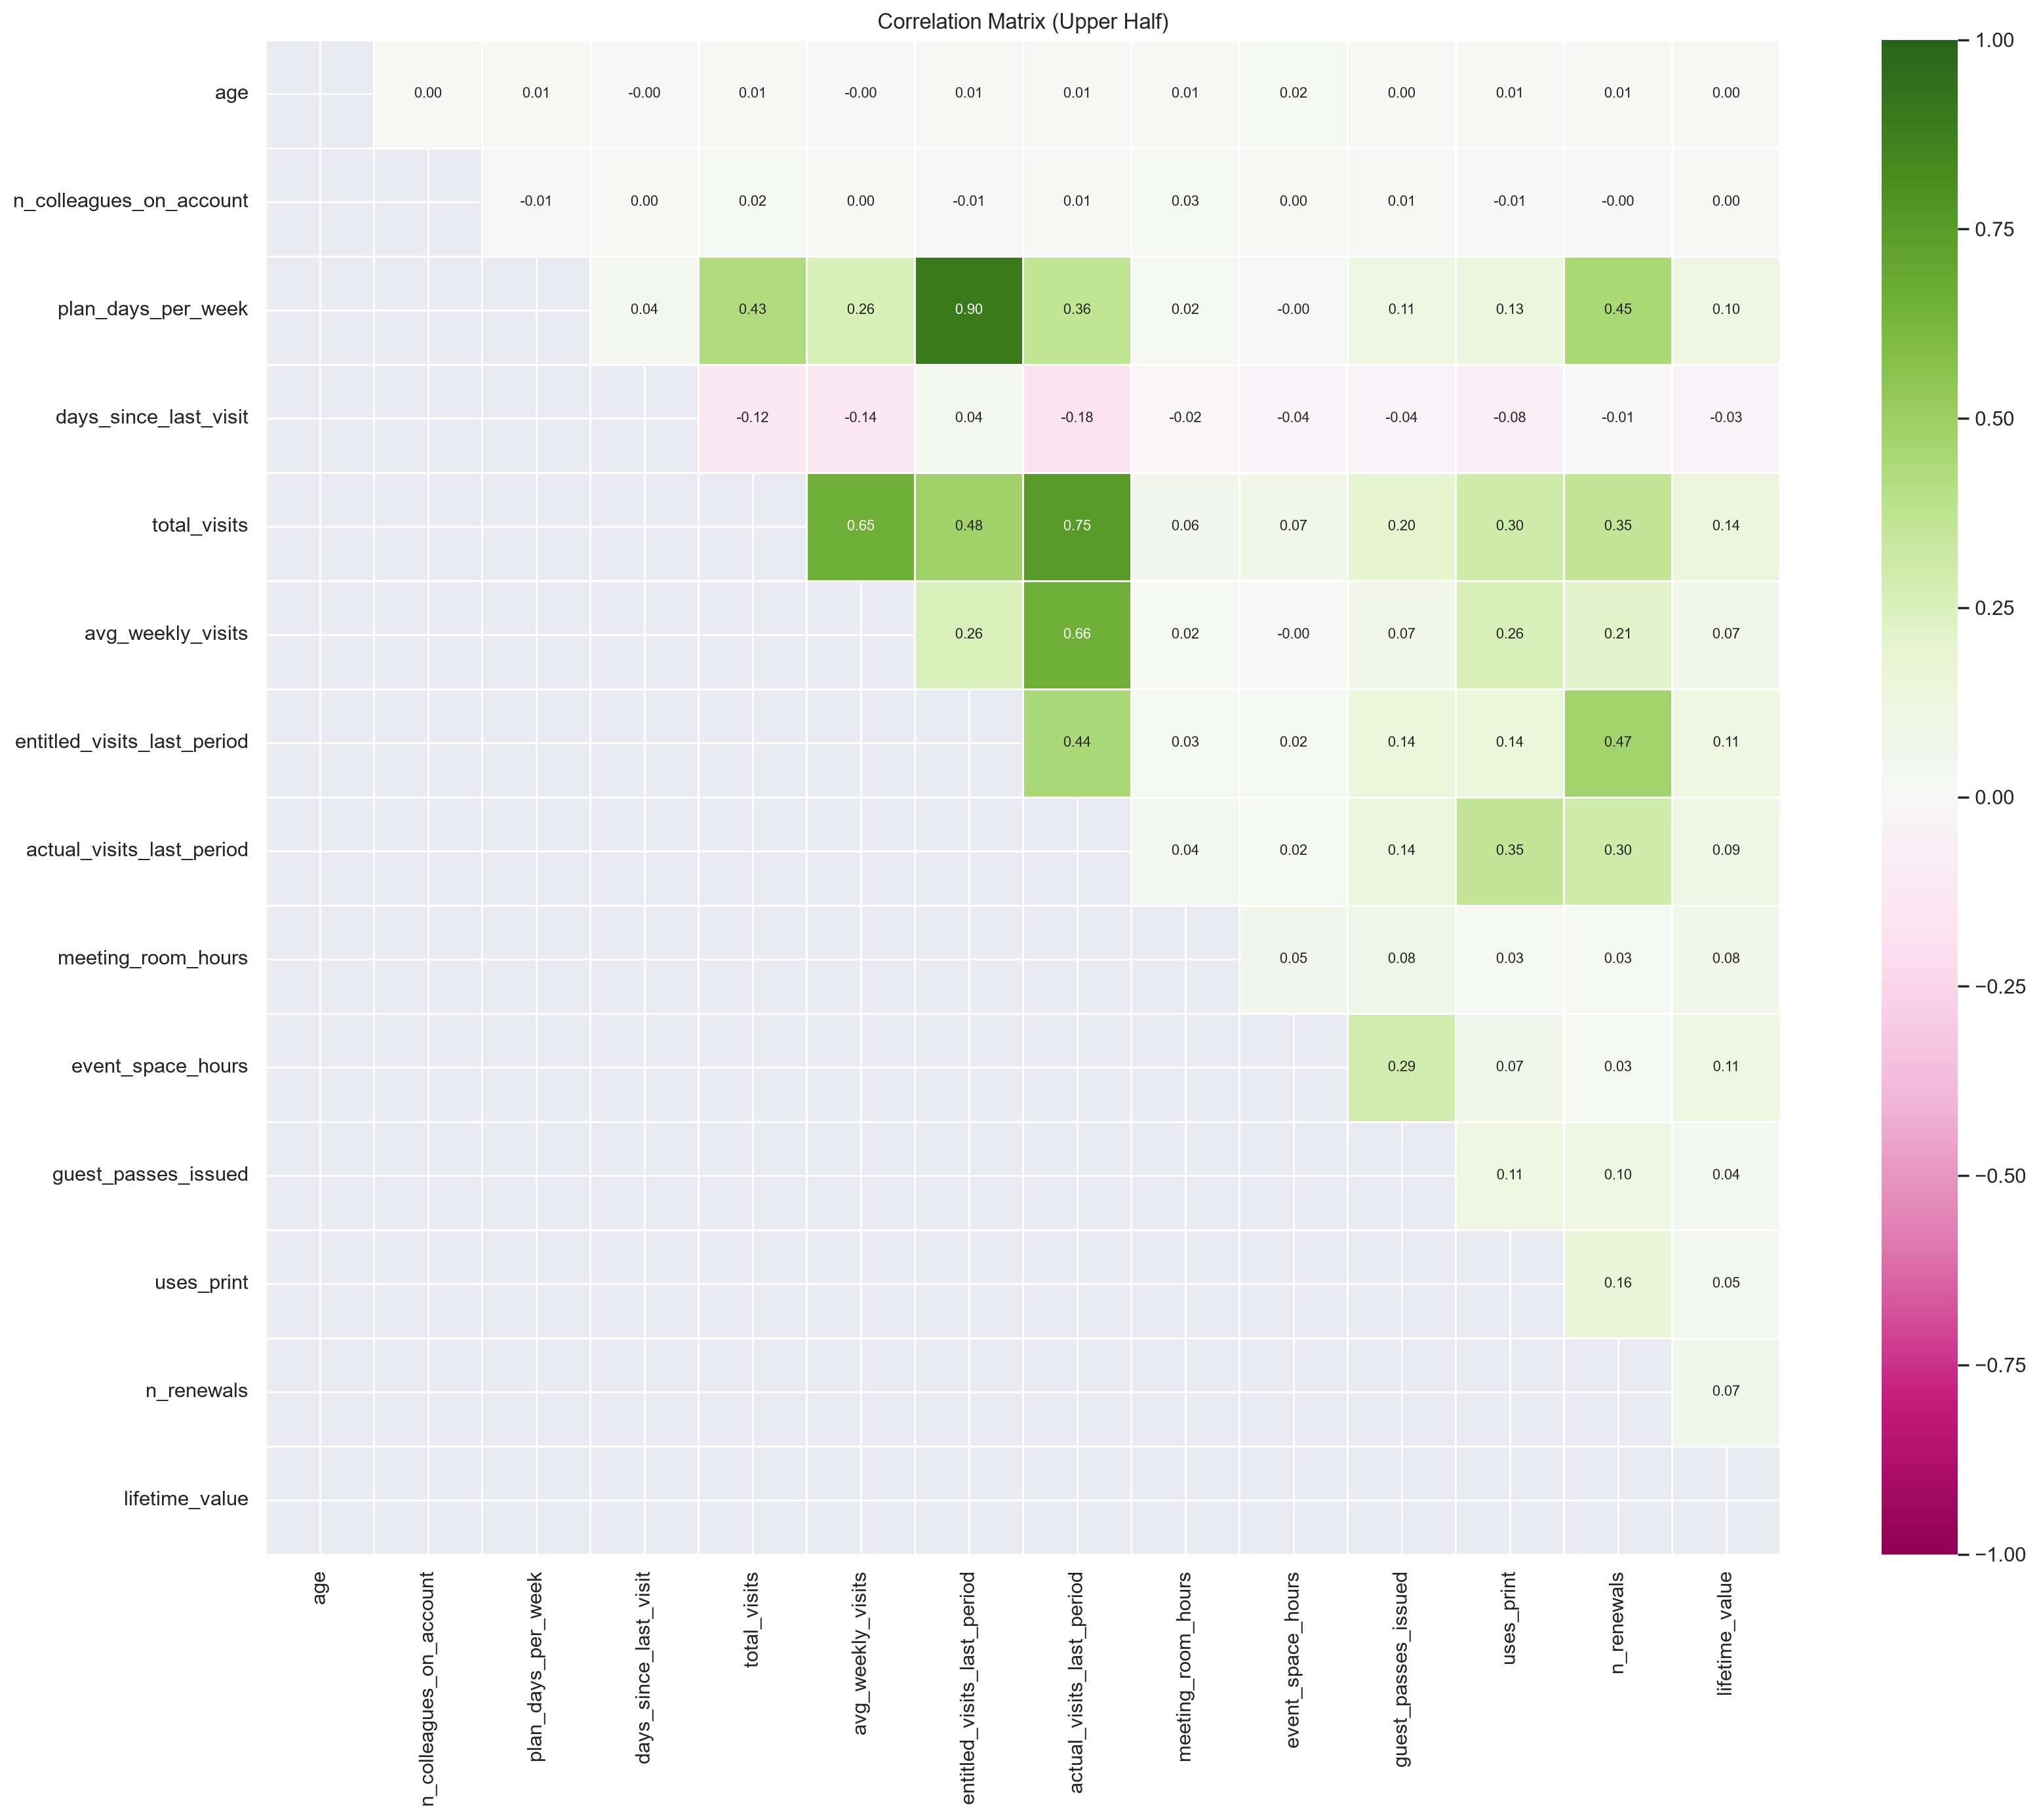

In [51]:

corr = df.select_dtypes(include=['float64', 'int64']).corr()

# OPÇÃO 1: HALF MATRIX (Inferior)
mask_lower = np.triu(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(20, 15))
sns.heatmap(corr, 
            mask=mask_lower, 
            annot=True,         
            annot_kws={"size": 8}, 
            cmap='PiYG', 
            fmt=".2f",           
            vmin=-1, vmax=1, 
            center=0,
            square=True,
            linewidths=.5)

plt.title('Correlation Matrix (Lower Half)')
plt.show()

# OPÇÃO 2: HALF MATRIX (Superior)
mask_upper = np.tril(np.ones_like(corr, dtype=bool))

plt.figure(figsize=(20, 15))
sns.heatmap(corr, 
            mask=mask_upper, 
            annot=True,         
            annot_kws={"size": 8}, 
            cmap='PiYG', 
            fmt=".2f",          
            vmin=-1, vmax=1, 
            center=0,
            square=True,
            linewidths=.5)

plt.title('Correlation Matrix (Upper Half)')
plt.show()



### Age

The IQR rule flags ages above 56.5 and below 12.5 as outliers. However, an age of 57 is not unrealistic: 
111 members are between 57 and 90 years old (median 59), which is plausible for a coworking space. 
For this variable, the IQR rule is too strict, so it is not used to remove observations.
The real problems are the ages above 90 (49 members, up to 149) and the ages below 16 (98 members), 
which are considered data errors.

<div style="border:2px solid #4a90d9; border-radius:6px; padding:12px; background-color:#eef5fc; color:#000000;">

<h3 style="margin-top:0;">Variable: lifetime_value</h3>

<b>What is it?</b> The total amount of money (in euros) that a member has brought to ACDC since joining.

<b>What are we doing?</b> We check whether the values are realistic, by looking at the smallest and the largest values.

<b>Steps:</b>
<ol>
<li>Look at the basic statistics (minimum, maximum, median)</li>
<li>Look at the 10 largest values</li>
<li>Count the negative values</li>
<li>Count the very large values</li>
<li>Check that the large values are consistent with the plan of the member</li>
</ol>


> ### Variable: lifetime_value
> **What is it?** The total amount of money (in euros) that a member has brought to ACDC since joining.
>
> **What are we doing?** We check whether the values are realistic, by looking at the smallest and the largest values.
>
> **Steps:** 1) basic statistics, 2) 10 largest values, 3) negative values, 4) very large values, 5) consistency with the plan.

#### Step 1: basic statistics

In [52]:
# Basic statistics of lifetime_value (min, max, mean, median...)
df["lifetime_value"].describe()

count     14410.00
mean       6398.77
std       62789.64
min      -13440.24
25%         252.73
50%         825.12
75%        5057.34
max     3371260.00
Name: lifetime_value, dtype: float64

In [53]:
# Basic statistics of lifetime_value, displayed with thousands separators
df["lifetime_value"].describe().apply(lambda x: f"{x:,.0f}")

count       14,410
mean         6,399
std         62,790
min        -13,440
25%            253
50%            825
75%          5,057
max      3,371,260
Name: lifetime_value, dtype: str

#### Step 2: the 10 largest values

In [54]:
# The 10 largest values
df["lifetime_value"].nlargest(10)

8454    3371260.00
12903   2532335.00
9717    2181450.00
13027   2084722.00
1619    1861269.00
9283    1712153.00
11092   1453134.00
374     1342807.00
12378   1296617.00
3287    1294678.00
Name: lifetime_value, dtype: float64

#### Step 3: negative values

In [55]:
# Number of negative values (an amount generated by a customer cannot be negative)
(df["lifetime_value"] < 0).sum()

np.int64(82)

#### Step 4: very large values

In [56]:
# Number of members with more than 100,000 euros
(df["lifetime_value"] > 100000).sum()

np.int64(47)

#### Step 5: consistency with the plan

In [57]:
# For each plan: number of members, typical value (median), largest value, 
# and number of members above 100,000 euros
by_plan = df.groupby("plan_tier")["lifetime_value"].agg(
    n_members="count",
    median="median",
    maximum="max",
    n_above_100k=lambda x: (x > 100000).sum(),
)

# Ratio: how many times larger is the maximum than the typical value of the plan?
by_plan["maximum_over_median"] = by_plan["maximum"] / by_plan["median"]

by_plan.round(0)

,n_members,median,maximum,n_above_100k,maximum_over_median
plan_tier,,,,,
dedicated_desk,1398,10348.00,1453134.00,5,140.00
flex,5089,1153.00,659184.00,19,571.00
full_time,2276,4613.00,3371260.00,10,731.00
hot_desk,4969,318.00,1201221.00,5,3772.00
private_office,592,19984.00,2181450.00,6,109.00


<div style="border:2px solid #2e8b57; border-radius:6px; padding:12px; background-color:#eefaf2; color:#000000;">

<b>Conclusion on lifetime_value</b><br>
The median lifetime value is ... euros, but the maximum is ... euros, which is not realistic for a coworking member. 
... members have a negative value (impossible) and ... members are above 100,000 euros. 
These very large values are not consistent with the plans (for example, the median of the hot_desk plan is only ... euros), 
so they are most likely data errors. They will be treated in the data preparation step.

</div>

<div style="border:2px solid #2e8b57; border-radius:6px; padding:12px; background-color:#eefaf2; color:#000000;">

<b>Conclusion on lifetime_value</b><br><br>

<b>What we observed:</b><br>
Lifetime value is available for 14,410 members. The median is 825 euros and 75% of the members are below 5,057 euros, 
so a typical member is worth a few hundred to a few thousand euros. The mean (6,399 euros) is much higher than the median 
because of a few very large values. The maximum is 3,371,260 euros, about 4,000 times the median, 
and the 10 largest values range from about 1.29 million to 3.37 million euros.<br><br>

<b>Impossible values:</b><br>
82 members have a negative lifetime value (the minimum is -13,440 euros), which is impossible 
since an amount generated by a customer cannot be negative.<br><br>

<b>Suspicious values:</b><br>
47 members (0.33% of the members with a value) have more than 100,000 euros. 
The threshold of 100,000 euros is a choice: it is far above what a typical member brings, 
but the distribution decreases gradually, so there is no single clear cut-off.<br><br>

<b>Consistency with the plan:</b><br>
The median lifetime value increases with the price of the plan, as expected: 
318 euros for hot_desk, 1,153 for flex, 4,613 for full_time, 10,348 for dedicated_desk and 19,984 for private_office. 
However, the extreme values are found in all five plans, even the cheapest ones: for example, 
a hot_desk member has 1,201,221 euros, which is 3,772 times the median of its plan, 
and a flex member has 659,184 euros. If these were real very valuable customers, 
they would be concentrated in the most expensive plans. Since they are spread across all plans, 
they are most likely data errors.<br><br>

<b>Decision:</b><br>
Negative values and values above 100,000 euros will be treated as errors (set to missing) in the data preparation step. 
Members with a lifetime value of zero (1,742 members) will be kept for now, but they should be checked, 
since the data does not say whether zero means "no revenue yet" or "unknown".

</div>

<div style="border:2px solid #4a90d9; border-radius:6px; padding:12px; background-color:#eef5fc; color:#000000;">

<h3 style="margin-top:0;">Variable: meeting_room_hours</h3>

<b>What is it?</b> The number of hours of meeting room used by the member. The data description does not say over which period the hours are counted.

<b>What are we doing?</b> We check whether the values are realistic, by looking at the smallest and the largest values.

<b>Steps:</b>
<ol>
<li>Look at the basic statistics (minimum, maximum, median)</li>
<li>Count the missing, zero and positive values</li>
<li>Count the negative values</li>
<li>Look at the largest values and count the impossible ones</li>
<li>Check which members have these very large values</li>
<li>Check the consistency with the variable uses_meeting_rooms</li>
</ol>

</div>

#### Step 1: basic statistics

In [58]:
# Basic statistics of meeting_room_hours, displayed with thousands separators
df["meeting_room_hours"].describe().apply(lambda x: f"{x:,.1f}")

count    14,155.0
mean         33.1
std         428.3
min         -56.6
25%           0.0
50%           0.0
75%           7.2
max      41,220.0
Name: meeting_room_hours, dtype: str

**Comment:** 14,155 members have a value. The median is 0 and 75% of the members are below 7.2 hours, 
but the maximum is 41,220 hours: the distribution is very unbalanced. More than half of the members never use a meeting room.

#### Step 2: missing, zero and positive values

In [59]:
# How many missing, zero and positive values?
hours = df["meeting_room_hours"]
print("Missing:", hours.isna().sum())
print("Zero:", (hours == 0).sum(), f"({(hours == 0).sum() / hours.notna().sum() * 100:.1f}% of the known values)")
print("Positive:", (hours > 0).sum())

Missing: 1295
Zero: 9242 (65.3% of the known values)
Positive: 4897


**Comment:** 1,295 values are missing and 9,242 members (65.3% of the known values) have 0 hours. 
Only 4,897 members have actually used a meeting room.

#### Step 3: negative values

In [60]:
# Number of negative values (a number of hours cannot be negative)
(df["meeting_room_hours"] < 0).sum()

np.int64(16)

**Comment:** 82 members have a negative lifetime value, which is impossible (an amount generated by a customer cannot be negative).

#### Step 4: largest values

In [61]:
# Number of members above different limits
print("Above 1,000 hours:", (df["meeting_room_hours"] > 1000).sum())
print("Above 8,760 hours:", (df["meeting_room_hours"] > 8760).sum())
print("Above 26,280 hours:", (df["meeting_room_hours"] > 26280).sum())

Above 1,000 hours: 19
Above 8,760 hours: 6
Above 26,280 hours: 1


**Comment:** 19 members are above 1,000 hours, 6 are above 8,760 hours (the number of hours in one year) 
and 1 member is above 26,280 hours (the number of hours in 3 years, the maximum length of a membership), 
which is impossible. 
8,760 hours spread over 3 years would mean about 8 hours per day, every day, which is possible on paper 
but not realistic for one member. The thresholds are indicative: the data description does not say over which period 
the hours are counted.

#### Step 5: who are the members with very large values?

In [62]:
# Plan of the members with more than 1,000 meeting room hours
df.loc[df["meeting_room_hours"] > 1000, "plan_tier"].value_counts()

plan_tier
flex              9
full_time         5
private_office    2
hot_desk          2
dedicated_desk    1
Name: count, dtype: int64

**Comment:** The 19 members are spread over all five plans (9 flex, 5 full_time, 2 private_office, 2 hot_desk, 1 dedicated_desk). 
They do not belong to a specific plan, and most of them are on the cheaper plans.

In [63]:
# Are they team accounts?
df.loc[df["meeting_room_hours"] > 1000, "is_team_account"].value_counts()

is_team_account
False    12
True      7
Name: count, dtype: int64

**Comment:** 12 of the 19 members are not team accounts. These are individual members, 
so heavy use by a team does not explain these values.

#### Step 6: consistency with uses_meeting_rooms

In [64]:
# Hours recorded although the member is flagged as not using meeting rooms
print(((df["meeting_room_hours"] > 0) & (~df["uses_meeting_rooms"])).sum())

# Flagged as using meeting rooms although the hours are zero
print(((df["meeting_room_hours"] == 0) & (df["uses_meeting_rooms"])).sum())

55
7


**Comment:** 55 members have meeting room hours although uses_meeting_rooms is False, and 7 members are flagged as users with 0 hours. 
The two variables are not fully consistent.

<div style="border:2px solid #2e8b57; border-radius:6px; padding:12px; background-color:#eefaf2; color:#000000;">

<b>Conclusion on meeting_room_hours</b><br><br>

<b>What we observed:</b><br>
Meeting room hours are available for 14,155 members (1,295 are missing, 8.4% of the data). 
The variable is strongly right-skewed: the median is 0 and 75% of the members are below 7.2 hours, 
but the mean is 33 hours and the maximum is 41,220 hours. 
65.3% of the known values are zero (9,242 members), so most members never use a meeting room, 
and only 4,897 members have a positive value.<br><br>

<b>Impossible values:</b><br>
16 members have a negative number of hours (minimum -56.6), which is impossible. 
One member has 41,220 hours, which is more than the number of hours in 3 years (26,280), 
the maximum length of a membership in the data. This is impossible whatever the period used.<br><br>

<b>Suspicious values:</b><br>
6 members are above 8,760 hours (the number of hours in one year), and 19 members are above 1,000 hours. 
Spread over 3 years, 8,760 hours would mean about 8 hours per day, every day, which is not realistic for one member. 
The thresholds are indicative, since the data description does not give the period over which the hours are counted. 
The 19 members above 1,000 hours are spread over all five plans (9 flex, 5 full_time, 2 private_office, 2 hot_desk, 1 dedicated_desk), 
and 12 out of 19 are not team accounts. They do not form a specific group of heavy users, 
so they are most likely data errors.<br><br>

<b>Inconsistencies:</b><br>
55 members have meeting room hours although uses_meeting_rooms is False, 
and 7 members are flagged as users with 0 hours.<br><br>

<b>Impact on the clustering:</b><br>
A few extreme values can dominate distance-based algorithms such as K-means, 
and the large number of zeros means that this variable mainly separates users from non-users.<br><br>

<b>Next step:</b><br>
These problems will be handled in the data preparation step: negative values and impossible values will be set to missing, 
and the suspicious values above 1,000 hours will be checked again (for example, by comparing the hours with the length of the membership) 
before deciding whether to remove or cap them. 
The zeros are real information (non-users) and will be kept.

</div>

# i do this more quickly maybe complete

In [65]:
# Remaining numeric variables to check
cols = ["total_visits", "days_since_last_visit", "avg_weekly_visits", "actual_visits_last_period",
        "entitled_visits_last_period", "n_renewals", "n_colleagues_on_account",
        "event_space_hours", "guest_passes_issued", "plan_days_per_week"]

# For each variable: smallest, typical (median) and largest value, and number of negative values
check = pd.DataFrame({
    "min": df[cols].min(),
    "median": df[cols].median(),
    "max": df[cols].max(),
    "n_negative": (df[cols] < 0).sum(),
})
check.round(1)

,min,median,max,n_negative
total_visits,-112.00,34.00,6530.00,42
days_since_last_visit,-956.00,13.00,1212.00,56
avg_weekly_visits,0.00,1.40,47.40,0
actual_visits_last_period,0.00,10.00,60.00,0
entitled_visits_last_period,0.00,26.10,78.30,0
n_renewals,-3.00,0.00,6.00,66
n_colleagues_on_account,-1.00,0.00,9.00,565
event_space_hours,-13.50,0.00,602.80,8
guest_passes_issued,-24.00,0.00,589.00,7
plan_days_per_week,0.00,3.00,9.00,0


**Comment:** Negative values appear in most count variables, which is impossible: total_visits (42 members), days_since_last_visit (56), 
n_renewals (66), event_space_hours (8) and guest_passes_issued (7). 
n_colleagues_on_account is -1 for 565 members, which is many more than the other cases, 
so it may be a code for "unknown" rather than random errors. 
Some maximums are very far from the median: total_visits (6,530 vs 34) and avg_weekly_visits (47.4 vs 1.4).

In [66]:
# Values that are logically impossible or suspicious
print("plan_days_per_week above 7 (a week has 7 days):", (df["plan_days_per_week"] > 7).sum())
print("avg_weekly_visits above 7 (more than one visit per day on average):", (df["avg_weekly_visits"] > 7).sum())
print("total_visits above 1,213 (more visits than days in the data):", (df["total_visits"] > 1213).sum())
print("actual visits above entitled visits:", (df["actual_visits_last_period"] > df["entitled_visits_last_period"]).sum())

plan_days_per_week above 7 (a week has 7 days): 54
avg_weekly_visits above 7 (more than one visit per day on average): 42
total_visits above 1,213 (more visits than days in the data): 7
actual visits above entitled visits: 8


**Comment:** 54 members have a plan with more than 7 days per week, which is impossible. 
42 members have more than 7 visits per week on average, and 7 members have more total visits than the number of days covered by the data. 
8 members made more visits than they were entitled to, which is possible but should be checked.

<div style="border:2px solid #2e8b57; border-radius:6px; padding:12px; background-color:#eefaf2; color:#000000;">

<b>Conclusion on the other numeric variables</b><br>
Negative values appear in most count variables (total_visits, days_since_last_visit, n_renewals, event_space_hours, guest_passes_issued), 
and some values are logically impossible (plan_days_per_week above 7, total visits above the number of days in the data). 
n_colleagues_on_account is -1 for 565 members, which probably is a code for "unknown". 
These errors will be handled in the data preparation step (set to missing).

</div>

In [70]:
PLAN_ORDER = ["hot_desk", "flex", "dedicated_desk", "full_time", "private_office"]

eda = df.copy()

# --- membership status (before touching the dates) ---
# 1970-01-01 is the placeholder for "no end date"; we assume these members are still active (to be confirmed)
eda["is_active"] = eda["membership_end"].dt.year == 1970
eda.loc[eda["is_active"], "membership_end"] = pd.NaT

# --- impossible / suspicious values -> missing (only in this copy) ---
nonneg_cols = ["n_colleagues_on_account", "days_since_last_visit", "total_visits", "avg_weekly_visits",
               "entitled_visits_last_period", "actual_visits_last_period", "meeting_room_hours",
               "event_space_hours", "guest_passes_issued", "n_renewals", "lifetime_value"]
for col in nonneg_cols:
    eda.loc[eda[col] < 0, col] = np.nan

eda.loc[(eda["age"] < 16) | (eda["age"] > 90), "age"] = np.nan
eda.loc[eda["plan_days_per_week"] > 7, "plan_days_per_week"] = np.nan
eda.loc[eda["lifetime_value"] > 100_000, "lifetime_value"] = np.nan
eda.loc[eda["meeting_room_hours"] > 1000, "meeting_room_hours"] = np.nan
eda.loc[eda["event_space_hours"] > 1000, "event_space_hours"] = np.nan
eda.loc[eda["avg_weekly_visits"] > 7, "avg_weekly_visits"] = np.nan
eda.loc[eda["total_visits"] > 1213, "total_visits"] = np.nan

print("Values hidden in the plot-only copy (compared with df):")
hidden = (eda[nonneg_cols + ["age", "plan_days_per_week"]].isna().sum()
          - df[nonneg_cols + ["age", "plan_days_per_week"]].isna().sum())
hidden[hidden > 0]

Values hidden in the plot-only copy (compared with df):


n_colleagues_on_account    565
days_since_last_visit       56
total_visits                49
avg_weekly_visits           42
meeting_room_hours          35
event_space_hours            8
guest_passes_issued          7
n_renewals                  66
lifetime_value             129
age                        147
plan_days_per_week          54
dtype: int64

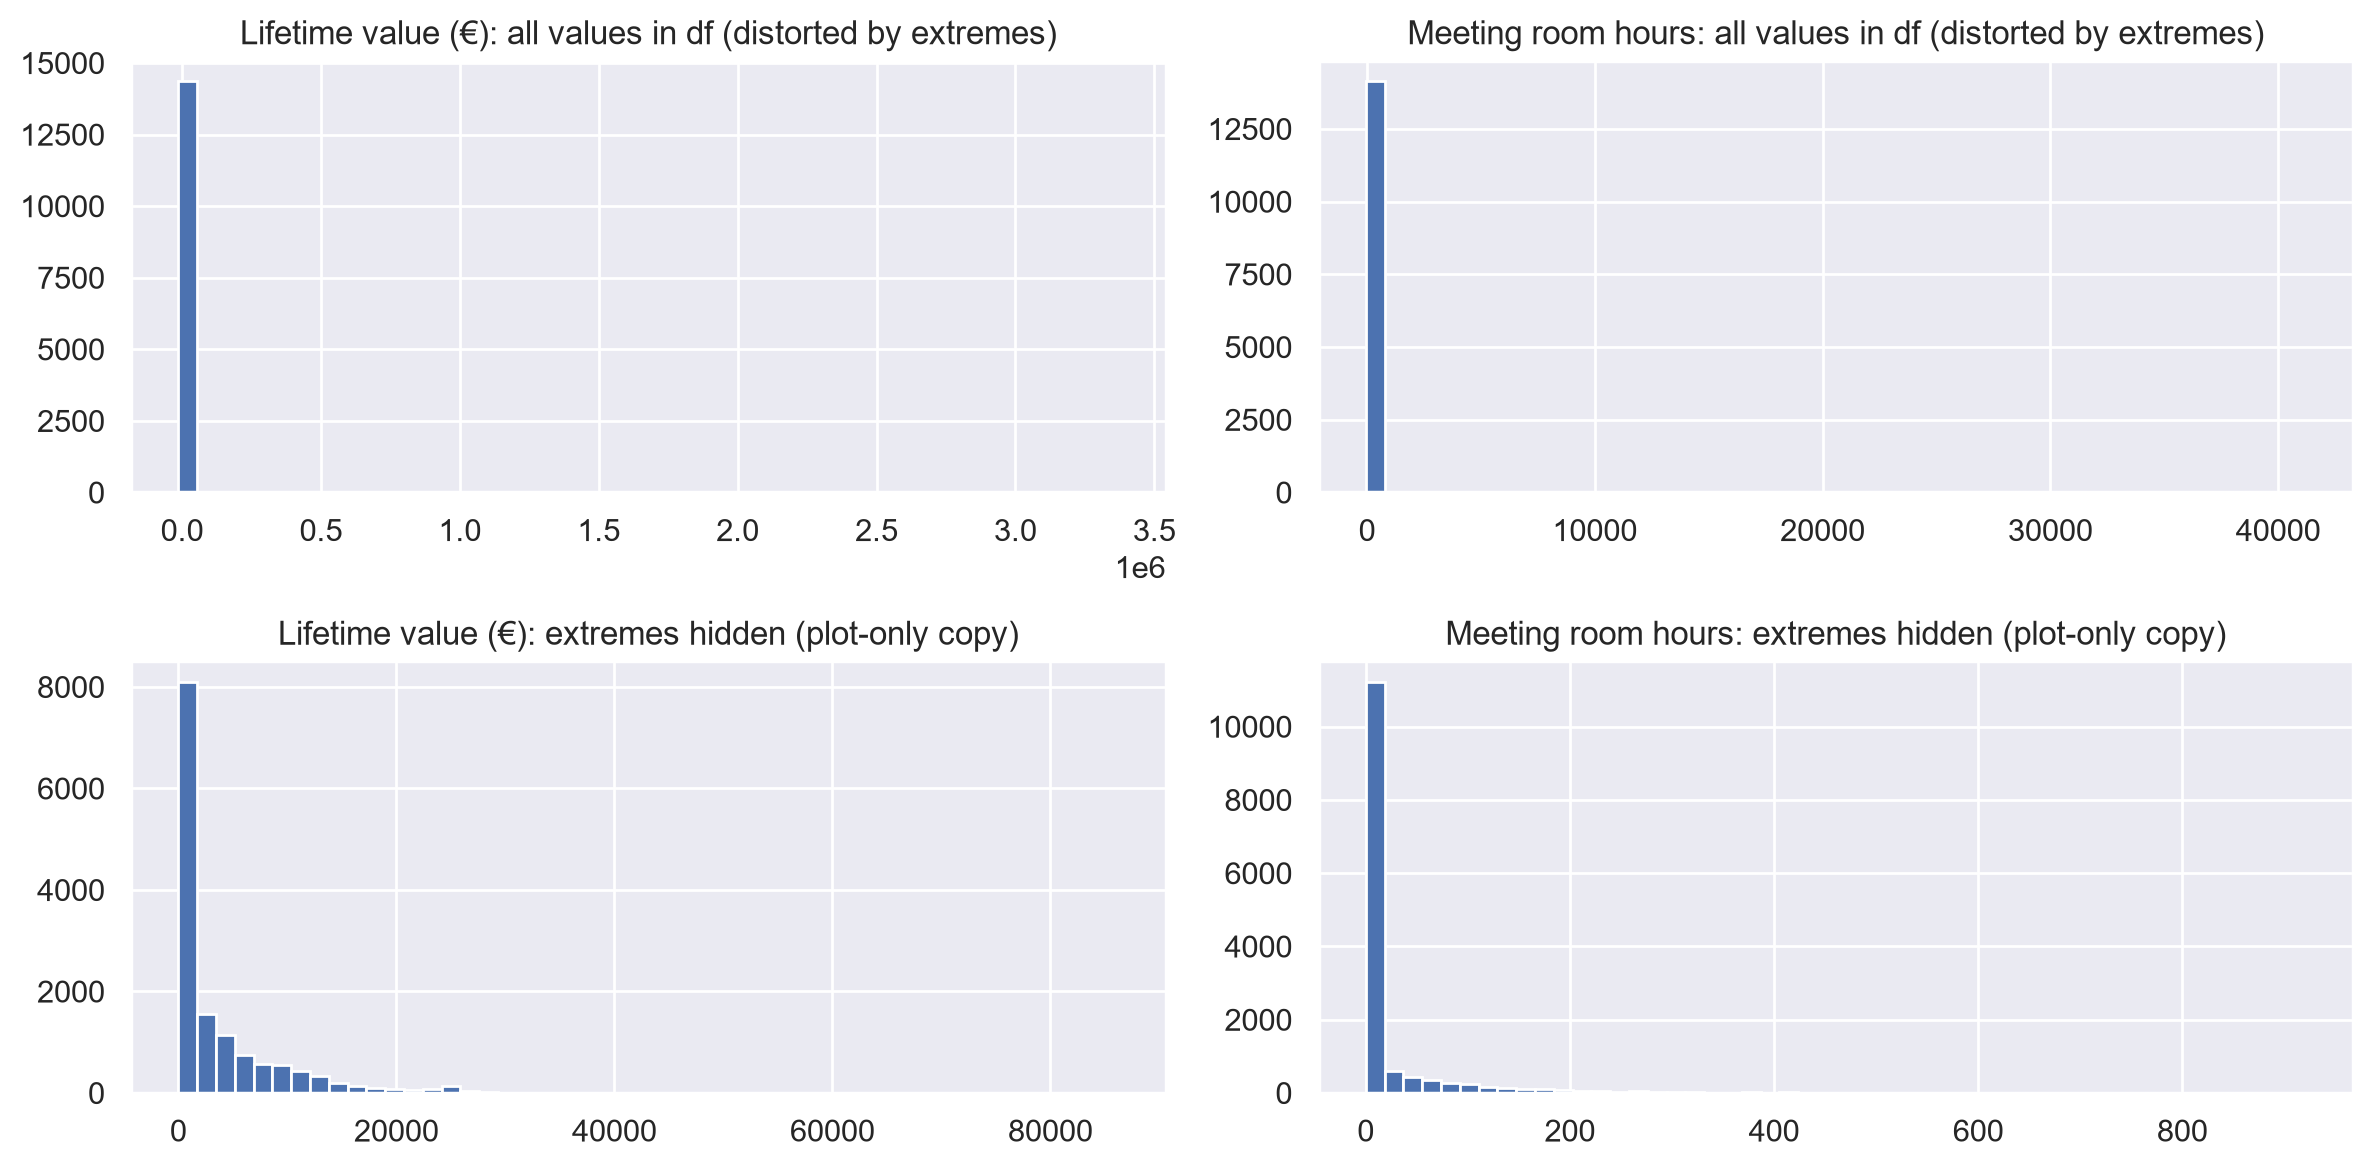

In [72]:
fig, axes = plt.subplots(2, 2, figsize=(12, 6))
for j, (col, title) in enumerate([("lifetime_value", "Lifetime value (€)"), ("meeting_room_hours", "Meeting room hours")]):
    axes[0, j].hist(df[col].dropna(), bins=50)
    axes[0, j].set_title(f"{title}: all values in df (distorted by extremes)")
    axes[1, j].hist(eda[col].dropna(), bins=50)
    axes[1, j].set_title(f"{title}: extremes hidden (plot-only copy)")
plt.tight_layout()
plt.show()

In [78]:
# Extraction date: last_badge_swipe + days_since_last_visit should give the same date for everybody
implied = (eda["last_badge_swipe"] + pd.to_timedelta(eda["days_since_last_visit"], unit="D")).dt.normalize()
print("Most common implied extraction dates:")
print(implied.value_counts().head(3))

Most common implied extraction dates:
2024-01-01    3376
2023-12-31     263
2023-11-28      29
Name: count, dtype: int64


In [79]:
# Reference date for active members = most common implied extraction date
# (fallback: the latest badge swipe)
ref_date = implied.mode().iloc[0] if implied.notna().any() else eda["last_badge_swipe"].max()
print("Reference date used:", ref_date.date())

end_or_ref = eda["membership_end"].fillna(ref_date)
eda["tenure_months"] = (end_or_ref - eda["membership_start"]).dt.days / 30.44
eda.loc[eda["tenure_months"] < 0, "tenure_months"] = np.nan

eda["utilisation"] = np.where(eda["entitled_visits_last_period"] > 0,
                              eda["actual_visits_last_period"] / eda["entitled_visits_last_period"], np.nan)

addon_cols = ["uses_meeting_rooms", "uses_event_space", "uses_guest_passes", "uses_print", "uses_mail_handling",
              "uses_phone_booths", "uses_day_passes", "uses_storage", "uses_bike_locker"]
eda["n_addons"] = eda[addon_cols].fillna(False).astype(bool).sum(axis=1)

eda["start_year"] = eda["membership_start"].dt.year
eda[["tenure_months", "utilisation", "n_addons"]].describe().T.round(2)

Reference date used: 2024-01-01


,count,mean,std,min,25%,50%,75%,max
tenure_months,15298.00,12.31,11.13,0.07,2.14,9.28,20.93,35.97
utilisation,15440.00,0.52,0.31,0.00,0.24,0.52,0.80,1.00
n_addons,15450.00,1.82,1.50,0.00,1.00,1.00,3.00,8.00


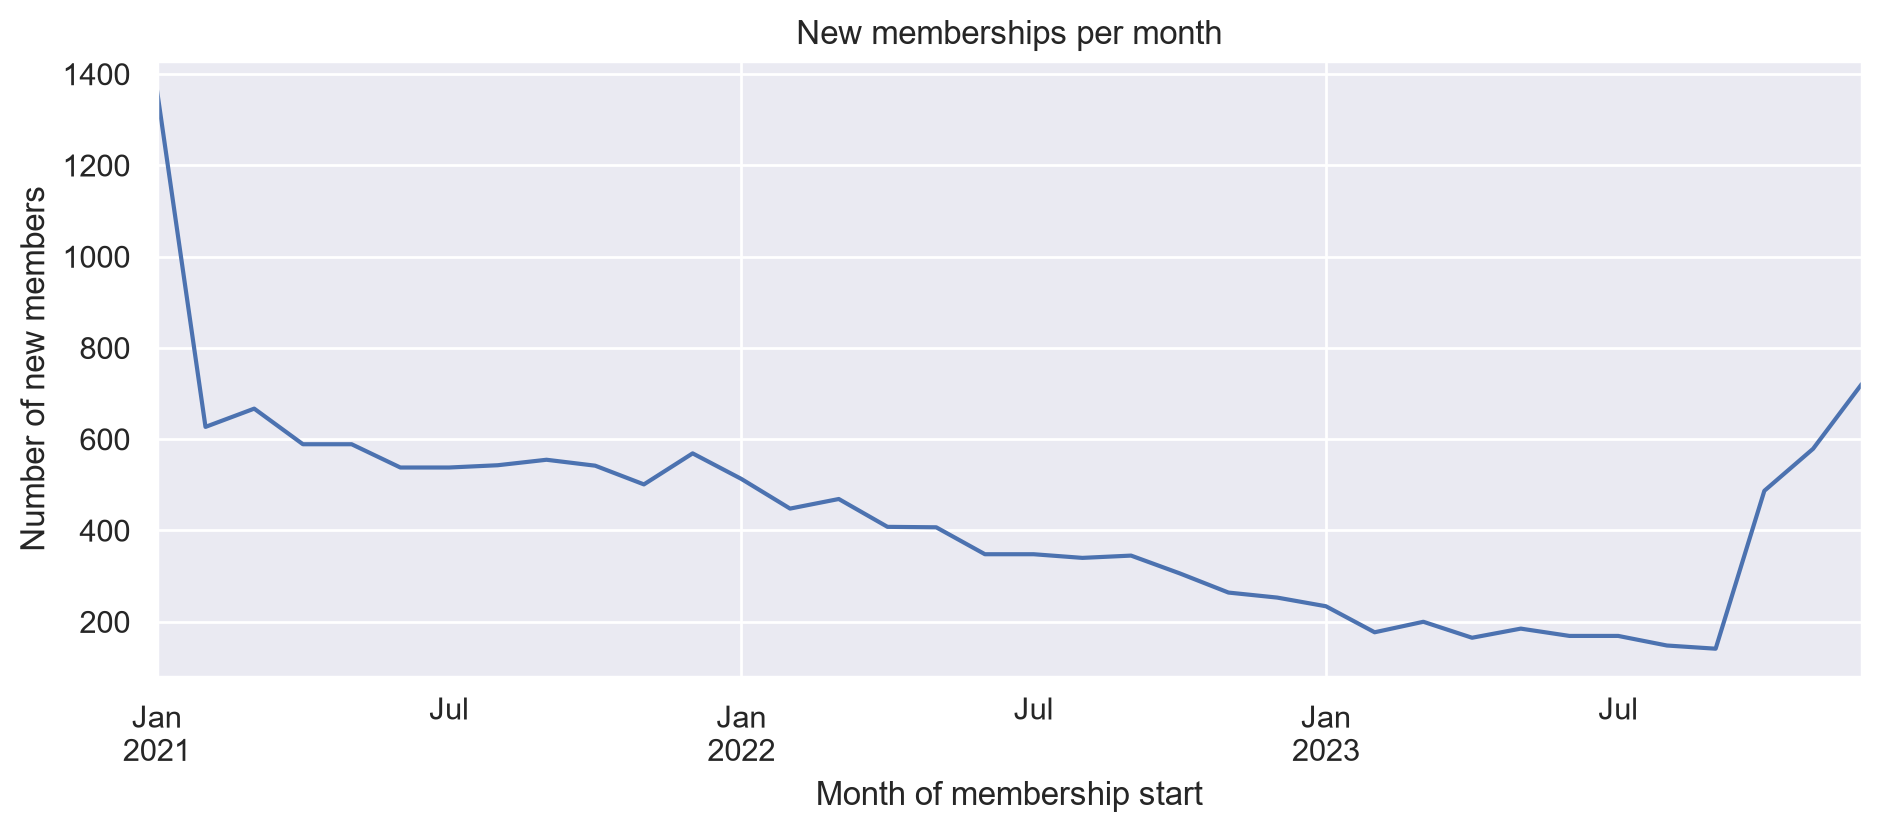

In [80]:
# New memberships per month
new_per_month = eda.groupby(eda["membership_start"].dt.to_period("M")).size()

plt.figure(figsize=(11, 4))
new_per_month.plot()
plt.title("New memberships per month")
plt.xlabel("Month of membership start")
plt.ylabel("Number of new members")
plt.show()

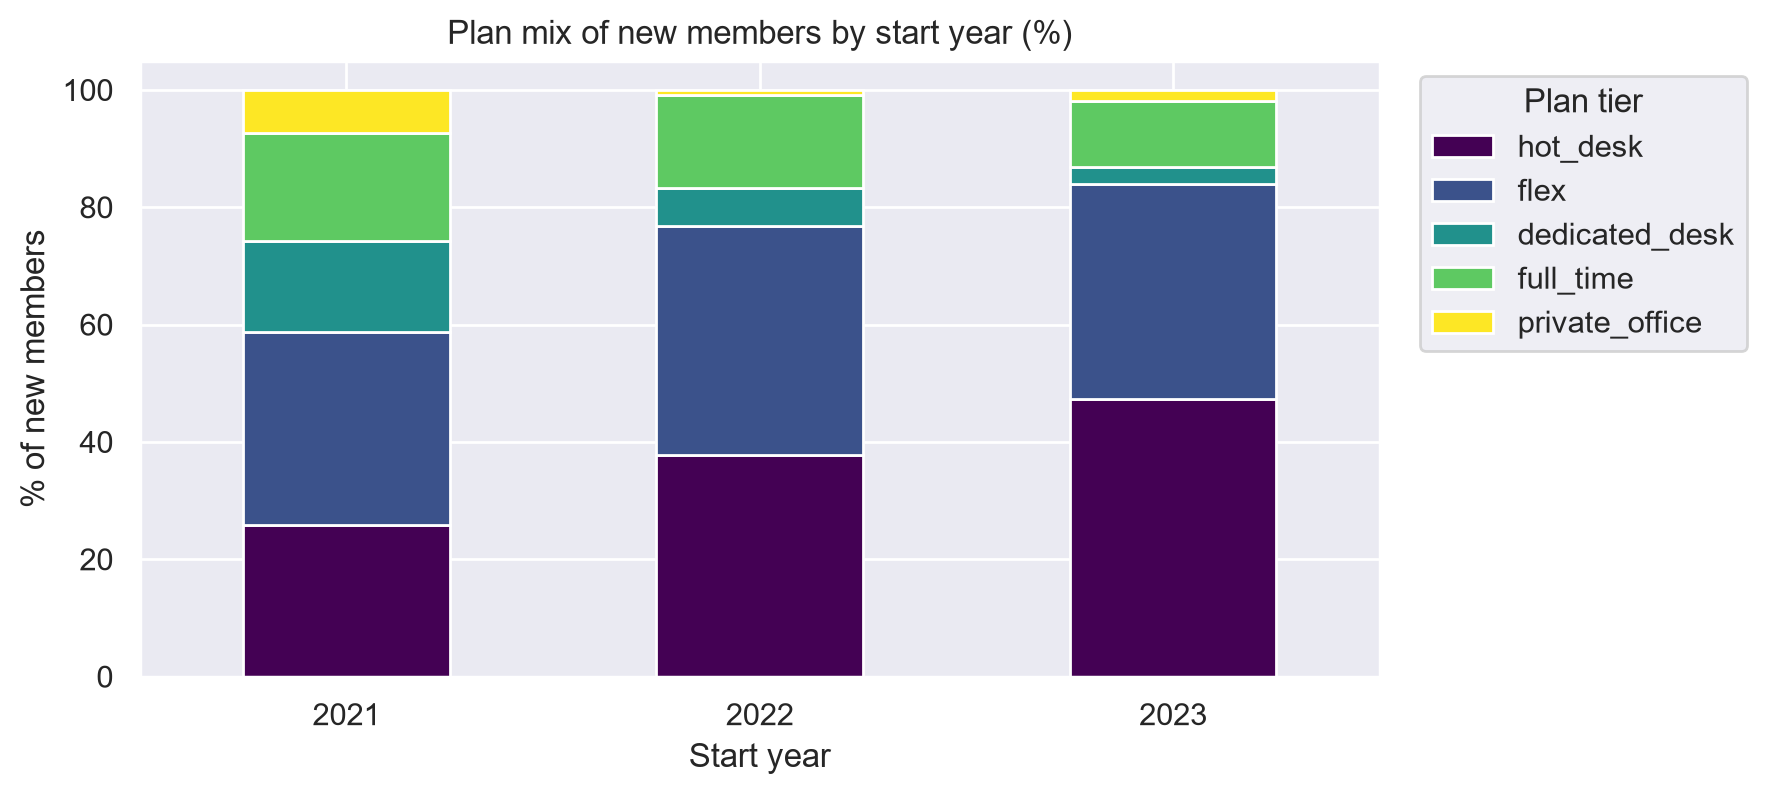

plan_tier,hot_desk,flex,dedicated_desk,full_time,private_office
start_year,,,,,
2021,25.80,33.00,15.40,18.40,7.40
2022,37.80,38.90,6.50,15.90,0.90
2023,47.30,36.70,2.90,11.20,1.90


In [81]:
# Mix of plans among new members, by start year (share of each plan in each year)
mix = (pd.crosstab(eda["start_year"], eda["plan_tier"], normalize="index")
         .reindex(columns=[p for p in PLAN_ORDER if p in eda["plan_tier"].unique()]) * 100)

mix.plot(kind="bar", stacked=True, figsize=(8, 4), colormap="viridis")
plt.title("Plan mix of new members by start year (%)")
plt.xlabel("Start year")
plt.ylabel("% of new members")
plt.legend(title="Plan tier", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.show()
mix.round(1)

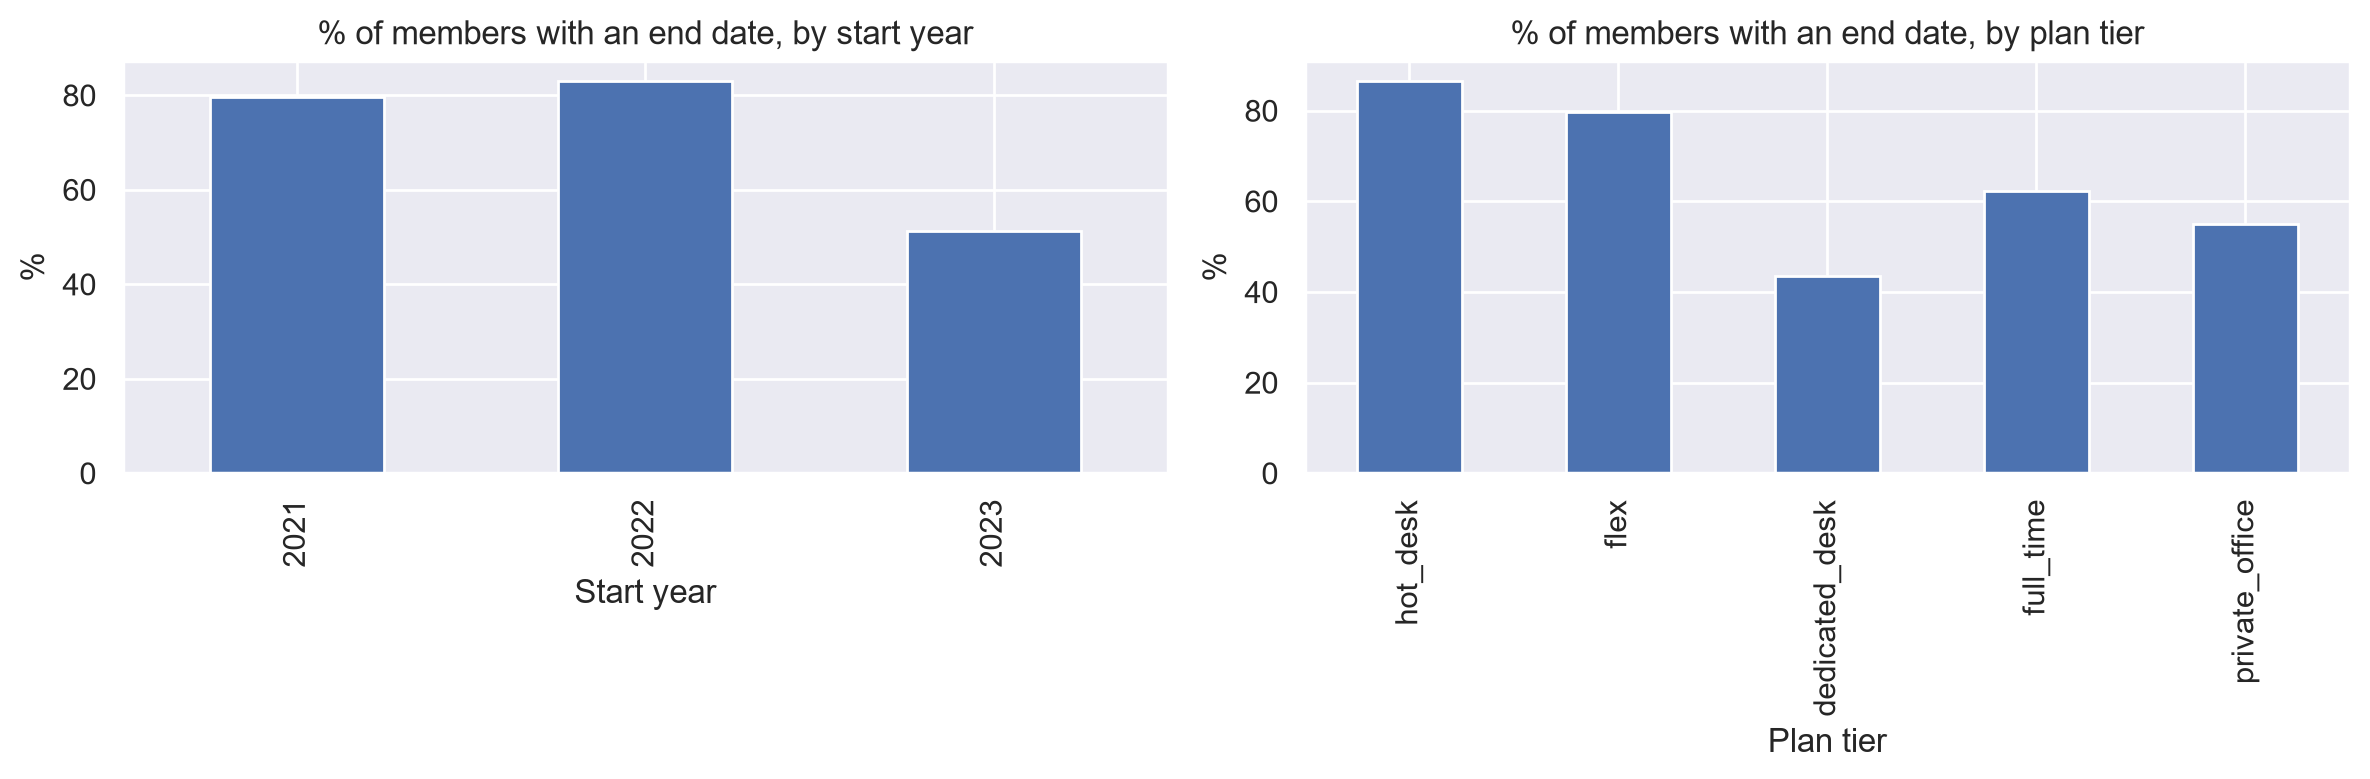

In [82]:
# Share of members who already ended their membership, by start year and by plan
ended_by_year = (1 - eda.groupby("start_year")["is_active"].mean()) * 100
ended_by_plan = ((1 - eda.groupby("plan_tier")["is_active"].mean()) * 100).reindex(PLAN_ORDER)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ended_by_year.plot(kind="bar", ax=axes[0])
axes[0].set_title("% of members with an end date, by start year")
axes[0].set_ylabel("%"); axes[0].set_xlabel("Start year")
ended_by_plan.plot(kind="bar", ax=axes[1])
axes[1].set_title("% of members with an end date, by plan tier")
axes[1].set_ylabel("%"); axes[1].set_xlabel("Plan tier")
plt.tight_layout()
plt.show()

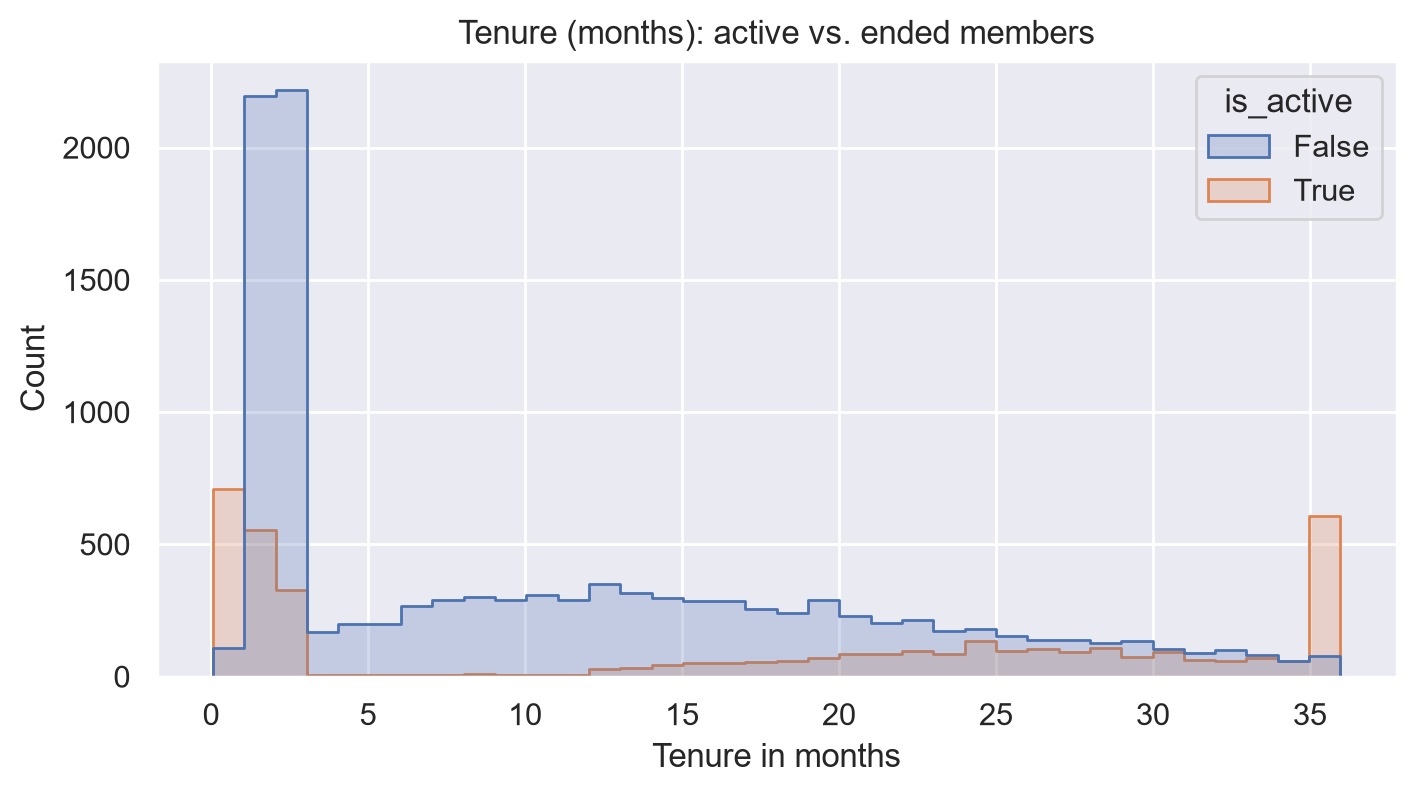

,count,mean,std,min,25%,50%,75%,max
is_active,,,,,,,,
False,11344.00,10.80,9.50,0.10,2.30,8.20,17.60,36.00
True,3954.00,16.70,13.90,0.10,1.50,19.10,29.30,36.00


In [83]:
# Tenure: active vs. ended members
plt.figure(figsize=(8, 4))
sns.histplot(data=eda, x="tenure_months", hue="is_active", bins=36, element="step", common_norm=False)
plt.title("Tenure (months): active vs. ended members")
plt.xlabel("Tenure in months")
plt.show()

eda.groupby("is_active")["tenure_months"].describe().round(1)

In [86]:
# Sanity check of the "active" assumption: do active members visit recently?
eda.groupby("is_active")["days_since_last_visit"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
is_active,,,,,,,,
False,11446.00,101.00,268.20,0.00,4.00,12.00,44.00,1002.00
True,3948.00,168.80,287.80,0.00,5.00,26.00,198.00,1212.00
